In [1]:
!jupyter nbconvert --to html Organized_Fruit_Vegetable_Freshness_Classification.ipynb

[NbConvertApp] Converting notebook Organized_Fruit_Vegetable_Freshness_Classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 15 image(s).
[NbConvertApp] Writing 3528740 bytes to Organized_Fruit_Vegetable_Freshness_Classification.html


# 🍎🥦 Fruit & Vegetable Freshness Classification
### Healthy vs Rotten — Classical CV + Transfer Learning (AlexNet / ResNet50 / MobileNetV2)

**Dataset:** [Fruit and Vegetable Disease (Healthy vs Rotten) — Kaggle](https://www.kaggle.com/datasets/muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten)
28 classes (14 fruits/vegetables × Healthy/Rotten)

| # | Person | Section |
|---|---|---|
| 1 | Somia | Data & EDA |
| 2 | Rawan | Classical CV Baseline |
| 3 | Hend | Transfer Learning — AlexNet |
| 4 | Menna | Transfer Learning — ResNet50 |
| 5 | Tasneem | Transfer Learning — MobileNetV2 |
| 6 | Toqa | Evaluation & Comparison |

## Setup
Imports all libraries used in the notebook, fixes the random `SEED` for reproducibility, and downloads the dataset from Kaggle.

In [1]:
import os
import time
import json
import random
import hashlib
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_recall_fscore_support
)
from skimage.feature import hog
from skimage.color import rgb2gray

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import kagglehub

# ---- Reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

plt.rcParams['figure.dpi'] = 100
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# ---- Download dataset from Kaggle ----
path = kagglehub.dataset_download("muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten")
BASE_PATH = os.path.join(path, "Fruit And Vegetable Diseases Dataset")
print("Dataset root:", BASE_PATH)


C:\Users\Toqa Mohamed Fathy\AppData\Roaming\Python\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu
Dataset root: C:\Users\Toqa Mohamed Fathy\.cache\kagglehub\datasets\muhammad0subhan\fruit-and-vegetable-disease-healthy-vs-rotten\versions\1\Fruit And Vegetable Diseases Dataset


## Section 1 — Data & EDA
Inspects the folder structure and class distribution (Healthy/Rotten), checks image integrity and resolution, explores color statistics visually and numerically, removes duplicates (MD5 + perceptual hash) before any splitting, builds a stratified `train/val/test` split (70/15/15), and designs a per-class augmentation strategy based on class size.

In [2]:
# List top-level folders (should be the 28 fruit/vegetable_condition categories)
top_level = sorted(os.listdir(BASE_PATH))
print(f"Number of top-level folders: {len(top_level)}\n")
for folder in top_level:
    folder_path = os.path.join(BASE_PATH, folder)
    if os.path.isdir(folder_path):
        n_files = len(os.listdir(folder_path))
        print(f"{folder:40s} → {n_files} files")

Number of top-level folders: 28

Apple__Healthy                           → 2438 files
Apple__Rotten                            → 2930 files
Banana__Healthy                          → 2000 files
Banana__Rotten                           → 2800 files
Bellpepper__Healthy                      → 611 files
Bellpepper__Rotten                       → 591 files
Carrot__Healthy                          → 620 files
Carrot__Rotten                           → 580 files
Cucumber__Healthy                        → 608 files
Cucumber__Rotten                         → 593 files
Grape__Healthy                           → 200 files
Grape__Rotten                            → 200 files
Guava__Healthy                           → 200 files
Guava__Rotten                            → 200 files
Jujube__Healthy                          → 200 files
Jujube__Rotten                           → 200 files
Mango__Healthy                           → 1813 files
Mango__Rotten                            → 2247 files
Orange_

In [3]:
# Build a structured DataFrame from folder names
records = []
for folder in top_level:
    folder_path = os.path.join(BASE_PATH, folder)
    if os.path.isdir(folder_path):
        n_files = len(os.listdir(folder_path))
        # Folder names look like "Apple__Healthy" or "Apple__Rotten"
        parts = folder.split("__")
        fruit = parts[0]
        condition = parts[1] if len(parts) > 1 else "Unknown"
        records.append({"folder": folder, "fruit": fruit, "condition": condition, "count": n_files})

df_counts = pd.DataFrame(records).sort_values(["fruit", "condition"]).reset_index(drop=True)
df_counts

,folder,fruit,condition,count
0,Apple__Healthy,Apple,Healthy,2438
1,Apple__Rotten,Apple,Rotten,2930
2,Banana__Healthy,Banana,Healthy,2000
3,Banana__Rotten,Banana,Rotten,2800
4,Bellpepper__Healthy,Bellpepper,Healthy,611
5,Bellpepper__Rotten,Bellpepper,Rotten,591
6,Carrot__Healthy,Carrot,Healthy,620
7,Carrot__Rotten,Carrot,Rotten,580
8,Cucumber__Healthy,Cucumber,Healthy,608
9,Cucumber__Rotten,Cucumber,Rotten,593


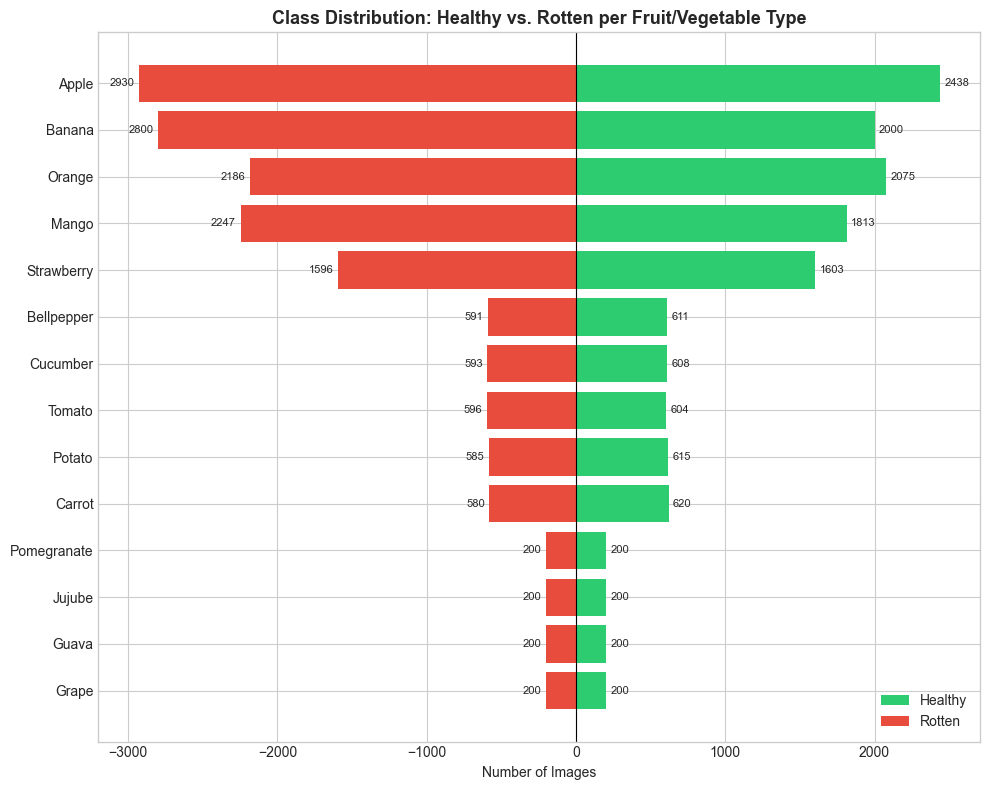

In [4]:
# Diverging bar chart: Healthy vs Rotten per fruit, sorted by total volume
pivot = df_counts.pivot(index="fruit", columns="condition", values="count").fillna(0)
pivot["total"] = pivot["Healthy"] + pivot["Rotten"]
pivot = pivot.sort_values("total", ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
y_pos = np.arange(len(pivot))

ax.barh(y_pos, pivot["Healthy"], color="#2ecc71", label="Healthy")
ax.barh(y_pos, -pivot["Rotten"], color="#e74c3c", label="Rotten")

ax.set_yticks(y_pos)
ax.set_yticklabels(pivot.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Number of Images")
ax.set_title("Class Distribution: Healthy vs. Rotten per Fruit/Vegetable Type",
             fontsize=13, fontweight="bold")
ax.legend(loc="lower right")

# Add value labels
for i, (h, r) in enumerate(zip(pivot["Healthy"], pivot["Rotten"])):
    ax.text(h + 30, i, f"{int(h)}", va="center", fontsize=8)
    ax.text(-r - 30, i, f"{int(r)}", va="center", ha="right", fontsize=8)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
import random

def check_integrity(base_path, top_level, sample_per_class=150, seed=42):
    random.seed(seed)
    corrupt_files = []
    hash_map = defaultdict(list)  # hash -> list of file paths (duplicate detection)

    for folder in top_level:
        folder_path = os.path.join(base_path, folder)
        if not os.path.isdir(folder_path):
            continue
        files = os.listdir(folder_path)
        sample = random.sample(files, min(sample_per_class, len(files)))

        for fname in sample:
            fpath = os.path.join(folder_path, fname)
            try:
                with Image.open(fpath) as img:
                    img.verify()  # checks file isn't corrupted
                # Compute hash for duplicate detection
                with open(fpath, "rb") as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()
                hash_map[file_hash].append(fpath)
            except Exception as e:
                corrupt_files.append((fpath, str(e)))

    duplicates = {h: paths for h, paths in hash_map.items() if len(paths) > 1}
    return corrupt_files, duplicates

corrupt_files, duplicates = check_integrity(BASE_PATH, top_level)

print(f"Corrupt/unreadable files found: {len(corrupt_files)}")
print(f"Duplicate groups found: {len(duplicates)}")
if duplicates:
    print("\nExample duplicate group:")
    first_key = list(duplicates.keys())[0]
    for p in duplicates[first_key]:
        print(" -", p)

Corrupt/unreadable files found: 0
Duplicate groups found: 26

Example duplicate group:
 - C:\Users\Toqa Mohamed Fathy\.cache\kagglehub\datasets\muhammad0subhan\fruit-and-vegetable-disease-healthy-vs-rotten\versions\1\Fruit And Vegetable Diseases Dataset\Bellpepper__Rotten\rottenPepper (168).jpg
 - C:\Users\Toqa Mohamed Fathy\.cache\kagglehub\datasets\muhammad0subhan\fruit-and-vegetable-disease-healthy-vs-rotten\versions\1\Fruit And Vegetable Diseases Dataset\Bellpepper__Rotten\rottenPepper (252).jpg


In [6]:
resolution_records = []

for folder in top_level:
    folder_path = os.path.join(BASE_PATH, folder)
    if not os.path.isdir(folder_path):
        continue
    files = os.listdir(folder_path)
    sample = random.sample(files, min(50, len(files)))

    for fname in sample:
        fpath = os.path.join(folder_path, fname)
        try:
            with Image.open(fpath) as img:
                resolution_records.append({
                    "class": folder,
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                    "format": img.format
                })
        except Exception:
            continue

df_res = pd.DataFrame(resolution_records)

print("Unique resolutions found:", df_res[["width","height"]].drop_duplicates().shape[0])
print("\nMost common resolutions:")
print(df_res.groupby(["width","height"]).size().sort_values(ascending=False).head(10))
print("\nColor modes found:")
print(df_res["mode"].value_counts())
print("\nFile formats found:")
print(df_res["format"].value_counts())

Unique resolutions found: 701

Most common resolutions:
width  height
224    224       351
100    100        93
4160   3120       32
275    183        29
480    322        27
320    258        23
1200   1600       14
848    480        13
1600   1200       11
259    194        11
dtype: int64

Color modes found:
mode
RGB     1365
RGBA      34
P          1
Name: count, dtype: int64

File formats found:
format
JPEG    1115
PNG      284
WEBP       1
Name: count, dtype: int64


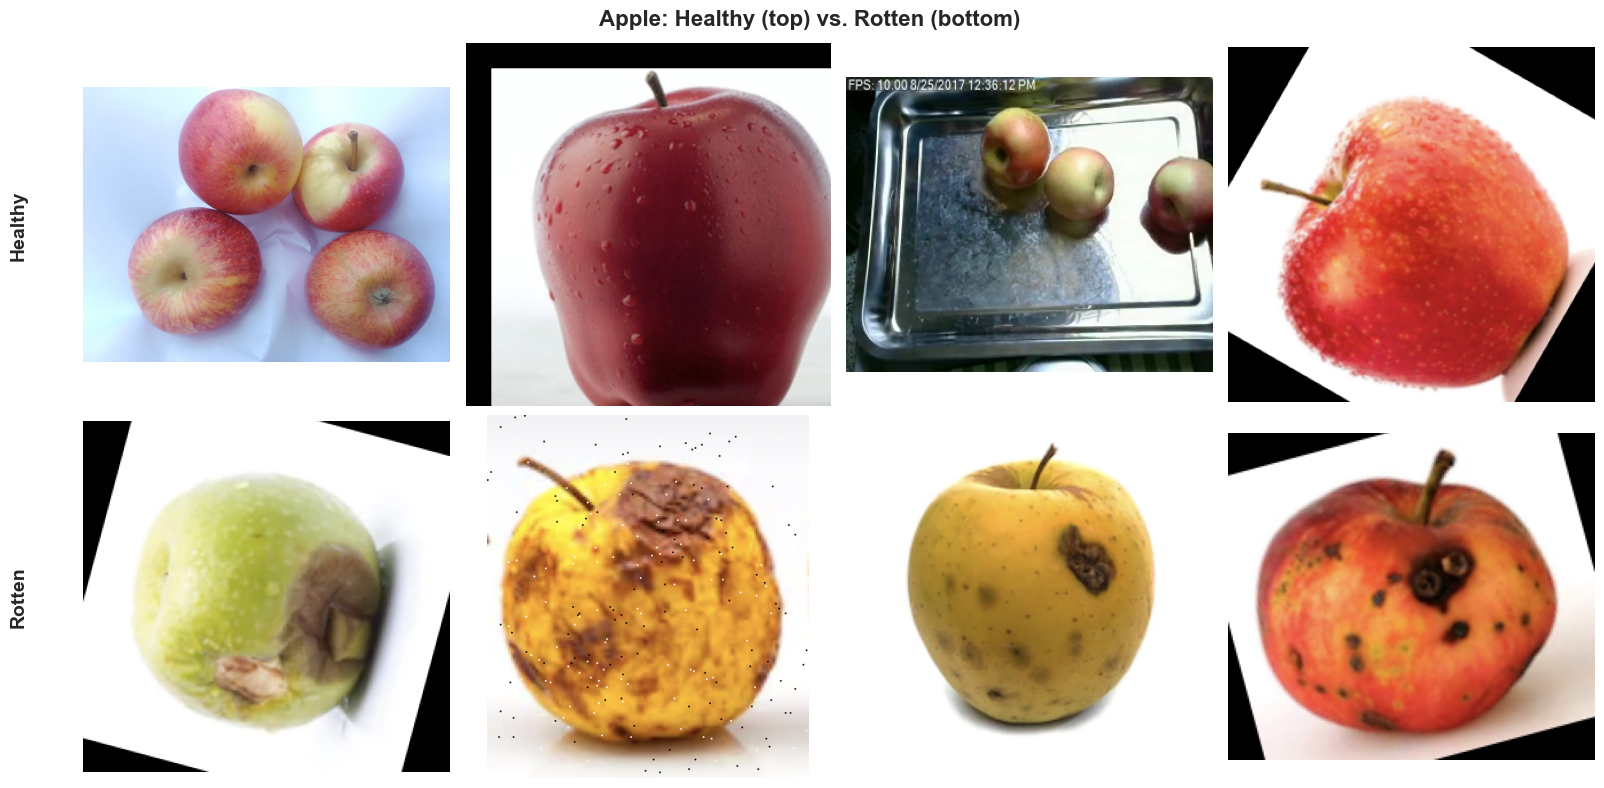

In [7]:
def show_sample_grid(base_path, fruit_name, n_samples=4):
    fig, axes = plt.subplots(2, n_samples, figsize=(4*n_samples, 8))
    for row, condition in enumerate(["Healthy", "Rotten"]):
        folder = f"{fruit_name}__{condition}"
        folder_path = os.path.join(base_path, folder)
        files = random.sample(os.listdir(folder_path), n_samples)
        for col, fname in enumerate(files):
            img = Image.open(os.path.join(folder_path, fname)).convert("RGB")
            axes[row, col].imshow(img)
            axes[row, col].axis("off")
            if col == 0:
                axes[row, col].set_ylabel(condition, fontsize=14, fontweight="bold")
        axes[row, 0].text(-0.15, 0.5, condition, transform=axes[row,0].transAxes,
                           fontsize=14, fontweight="bold", va="center", ha="right", rotation=90)
    plt.suptitle(f"{fruit_name}: Healthy (top) vs. Rotten (bottom)", fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"sample_grid_{fruit_name}.png", dpi=150, bbox_inches="tight")
    plt.show()

show_sample_grid(BASE_PATH, "Apple")

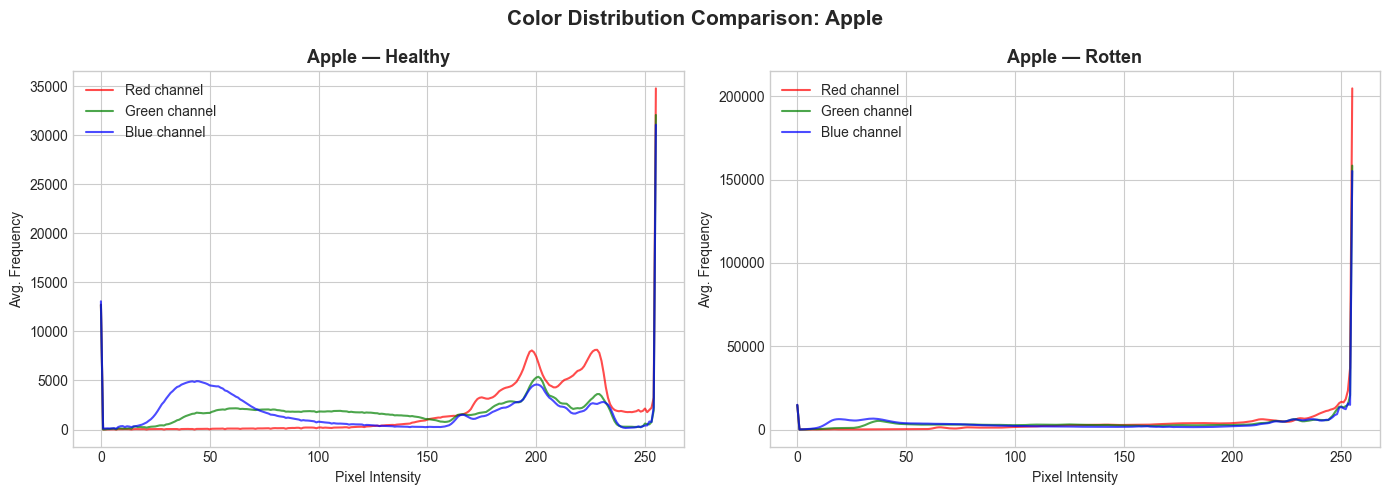

In [8]:
def plot_color_histogram_comparison(base_path, fruit_name, n_samples=30):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, condition in zip(axes, ["Healthy", "Rotten"]):
        folder = f"{fruit_name}__{condition}"
        folder_path = os.path.join(base_path, folder)
        files = random.sample(os.listdir(folder_path), min(n_samples, len(os.listdir(folder_path))))

        hist_r, hist_g, hist_b = np.zeros(256), np.zeros(256), np.zeros(256)
        for fname in files:
            img = Image.open(os.path.join(folder_path, fname)).convert("RGB")
            arr = np.array(img)
            hist_r += np.histogram(arr[:,:,0], bins=256, range=(0,256))[0]
            hist_g += np.histogram(arr[:,:,1], bins=256, range=(0,256))[0]
            hist_b += np.histogram(arr[:,:,2], bins=256, range=(0,256))[0]

        ax.plot(hist_r / n_samples, color='red', alpha=0.7, label='Red channel')
        ax.plot(hist_g / n_samples, color='green', alpha=0.7, label='Green channel')
        ax.plot(hist_b / n_samples, color='blue', alpha=0.7, label='Blue channel')
        ax.set_title(f"{fruit_name} — {condition}", fontsize=13, fontweight="bold")
        ax.set_xlabel("Pixel Intensity")
        ax.set_ylabel("Avg. Frequency")
        ax.legend()

    plt.suptitle(f"Color Distribution Comparison: {fruit_name}", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"color_hist_{fruit_name}.png", dpi=150, bbox_inches="tight")
    plt.show()

plot_color_histogram_comparison(BASE_PATH, "Apple")

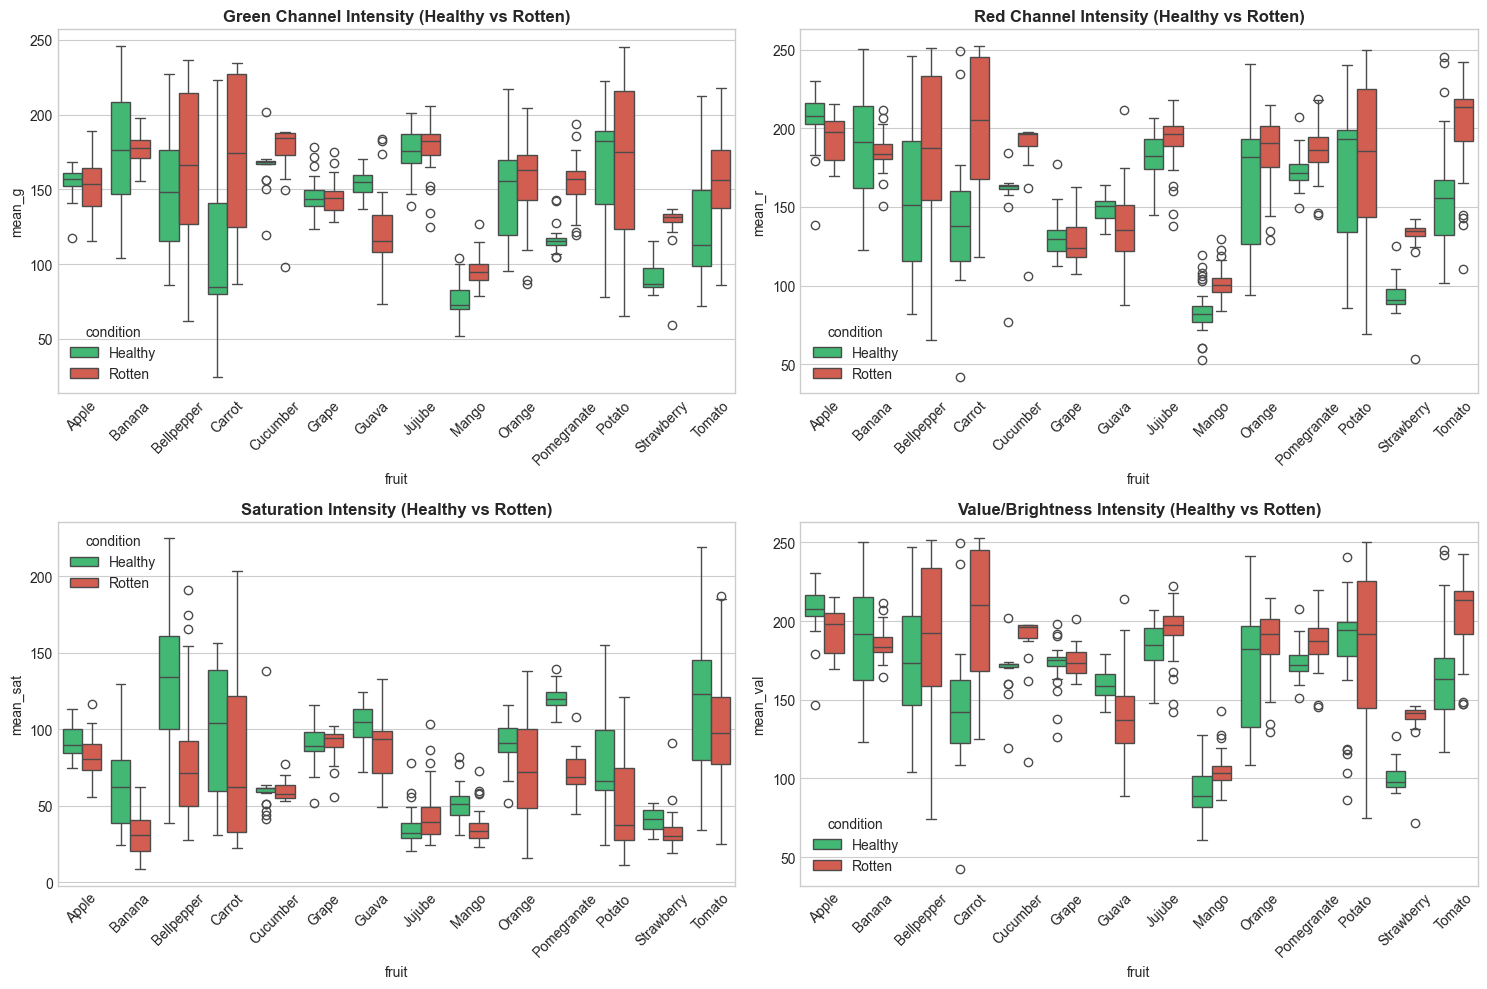


 STATISTICAL NUMERICAL INSIGHTS (HEALTHY vs ROTTEN MEAN VALUES)


mean_r         mean_g         mean_b        mean_sat         \
             mean    std    mean    std    mean    std     mean    std   
condition                                                                
Healthy    154.42  43.07  138.78  40.10  119.08  40.28    84.40  38.47   
Rotten     171.05  42.42  153.06  37.77  142.58  40.85    65.86  34.13   

          mean_val         
              mean    std  
condition                  
Healthy     163.45  40.18  
Rotten      176.99  38.74

In [9]:
def analyze_color_distribution(df, sample_per_class=30):
    stats = []

    for _, row in df.iterrows():
        folder_path = os.path.join(BASE_PATH, row['folder'])
        if not os.path.exists(folder_path): continue
        files = os.listdir(folder_path)[:sample_per_class]

        for file in files:
            img_path = os.path.join(folder_path, file)
            img = cv2.imread(img_path)
            if img is None: continue

            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

            stats.append({
                'fruit': row['fruit'],
                'condition': row['condition'],
                'mean_r': img_rgb[:,:,0].mean(),
                'mean_g': img_rgb[:,:,1].mean(),
                'mean_b': img_rgb[:,:,2].mean(),
                'mean_hue': img_hsv[:,:,0].mean(),
                'mean_sat': img_hsv[:,:,1].mean(),
                'mean_val': img_hsv[:,:,2].mean()
            })

    return pd.DataFrame(stats)

# Extract Statistics using df_counts
df_color_stats = analyze_color_distribution(df_counts, sample_per_class=30)

# Visualizing RGB & HSV Channel Distributions between Healthy vs Rotten
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# RGB Mean Distribution
sns.boxplot(data=df_color_stats, x='fruit', y='mean_g', hue='condition', palette=['#2ecc71', '#e74c3c'], ax=axes[0,0])
axes[0,0].set_title('Green Channel Intensity (Healthy vs Rotten)', fontweight='bold')
axes[0,0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df_color_stats, x='fruit', y='mean_r', hue='condition', palette=['#2ecc71', '#e74c3c'], ax=axes[0,1])
axes[0,1].set_title('Red Channel Intensity (Healthy vs Rotten)', fontweight='bold')
axes[0,1].tick_params(axis='x', rotation=45)

# HSV Saturation & Value
sns.boxplot(data=df_color_stats, x='fruit', y='mean_sat', hue='condition', palette=['#2ecc71', '#e74c3c'], ax=axes[1,0])
axes[1,0].set_title('Saturation Intensity (Healthy vs Rotten)', fontweight='bold')
axes[1,0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df_color_stats, x='fruit', y='mean_val', hue='condition', palette=['#2ecc71', '#e74c3c'], ax=axes[1,1])
axes[1,1].set_title('Value/Brightness Intensity (Healthy vs Rotten)', fontweight='bold')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Print Numeric Statistical Summary Table
print("\n" + "="*70)
print(" STATISTICAL NUMERICAL INSIGHTS (HEALTHY vs ROTTEN MEAN VALUES)")
print("="*70)
numeric_summary = df_color_stats.groupby(['condition'])[['mean_r', 'mean_g', 'mean_b', 'mean_sat', 'mean_val']].agg(['mean', 'std']).round(2)
display(numeric_summary)

In [10]:
all_records = []
for folder in top_level:
    folder_path = os.path.join(BASE_PATH, folder)
    if not os.path.isdir(folder_path):
        continue
    parts = folder.split("__")
    fruit, condition = parts[0], parts[1] if len(parts) > 1 else "Unknown"
    for fname in os.listdir(folder_path):
        if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
            all_records.append({
                "filepath": os.path.join(folder_path, fname),
                "fruit": fruit,
                "condition": condition,
                "class_label": folder
            })

df_full = pd.DataFrame(all_records)
print(f"[+] Total images indexed (before cleanup): {len(df_full):,}")

[+] Total images indexed (before cleanup): 29,277


In [11]:
seen_hashes = {}
keep_mask = []
exact_dup_count = 0

for fpath in df_full["filepath"]:
    try:
        with open(fpath, "rb") as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        if file_hash in seen_hashes:
            keep_mask.append(False)
            exact_dup_count += 1
        else:
            seen_hashes[file_hash] = True
            keep_mask.append(True)
    except Exception:
        keep_mask.append(False)

df_full = df_full[keep_mask].reset_index(drop=True)
print(f"[+] Exact (MD5) duplicates removed: {exact_dup_count}")
print(f"[+] Images remaining: {len(df_full):,}")

[+] Exact (MD5) duplicates removed: 1775
[+] Images remaining: 27,502


In [12]:
!pip install imagehash --quiet
import imagehash
from PIL import Image as PILImage

def compute_phash(filepath):
    try:
        img = PILImage.open(filepath).convert("RGB")
        return str(imagehash.phash(img))
    except Exception:
        return None

phash_map = defaultdict(list)
for idx, fpath in enumerate(df_full["filepath"]):
    ph = compute_phash(fpath)
    if ph:
        phash_map[ph].append(idx)

near_duplicate_groups = {h: idxs for h, idxs in phash_map.items() if len(idxs) > 1}
print(f"[+] Near-duplicate groups found: {len(near_duplicate_groups)}")

indices_to_drop = []
for h, idxs in near_duplicate_groups.items():
    indices_to_drop.extend(idxs[1:])  # keep first occurrence only

df_full = df_full.drop(index=indices_to_drop).reset_index(drop=True)
print(f"[+] Near-duplicates removed: {len(indices_to_drop)}")
print(f"[+] Final clean dataset size: {len(df_full):,}")


[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\Toqa Mohamed Fathy\AppData\Roaming\Python\Python310\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


[+] Near-duplicate groups found: 1408
[+] Near-duplicates removed: 1634
[+] Final clean dataset size: 25,868


In [13]:
 from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_full, test_size=0.30, stratify=df_full["class_label"], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["class_label"], random_state=42
)

print(f"[+] Total Images Indexed (after cleanup): {len(df_full):,}")
print(f"[+] Train Set: {len(train_df):,} samples ({len(train_df)/len(df_full)*100:.1f}%)")
print(f"[+] Validation Set: {len(val_df):,} samples ({len(val_df)/len(df_full)*100:.1f}%)")
print(f"[+] Test Set: {len(test_df):,} samples ({len(test_df)/len(df_full)*100:.1f}%)")

# Sanity check: class proportions should match closely across splits
comparison = pd.DataFrame({
    "train": train_df["class_label"].value_counts(normalize=True),
    "val": val_df["class_label"].value_counts(normalize=True),
    "test": test_df["class_label"].value_counts(normalize=True)
}).head(6)
print("\nClass proportion check (first 6 classes):")
print(comparison)

[+] Total Images Indexed (after cleanup): 25,868
[+] Train Set: 18,107 samples (70.0%)
[+] Validation Set: 3,880 samples (15.0%)
[+] Test Set: 3,881 samples (15.0%)

Class proportion check (first 6 classes):
                        train       val      test
class_label                                      
Apple__Healthy       0.087038  0.087113  0.087091
Apple__Rotten        0.101618  0.101546  0.101520
Banana__Healthy      0.077152  0.077062  0.077300
Banana__Rotten       0.100735  0.100773  0.100747
Bellpepper__Healthy  0.021373  0.021392  0.021386
Bellpepper__Rotten   0.019716  0.019845  0.019583


In [14]:
import json

# Create shared splits directory
os.makedirs("splits", exist_ok=True)

# Save the exact Train / Validation / Test splits
train_df.to_csv("splits/train_df.csv", index=False)
val_df.to_csv("splits/val_df.csv", index=False)
test_df.to_csv("splits/test_df.csv", index=False)

# Create a shared class-to-index mapping
classes = sorted(df_full["class_label"].unique())
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}

with open("splits/class_to_idx.json", "w") as f:
    json.dump(class_to_idx, f, indent=2)

print(" Shared split files saved successfully:")
print("   - splits/train_df.csv")
print("   - splits/val_df.csv")
print("   - splits/test_df.csv")
print("   - splits/class_to_idx.json")

print("\nThese files must be used by ALL team members (Tasks 2-5)")
print("to guarantee the same data split and class mapping.")

 Shared split files saved successfully:
   - splits/train_df.csv
   - splits/val_df.csv
   - splits/test_df.csv
   - splits/class_to_idx.json

These files must be used by ALL team members (Tasks 2-5)
to guarantee the same data split and class mapping.


In [15]:
import torchvision.transforms as transforms

MINORITY_CLASSES = ['Grape', 'Guava', 'Jujube', 'Pomegranate']
ROUND_SYMMETRIC_FRUITS = ['Apple', 'Orange', 'Grape', 'Guava', 'Pomegranate', 'Tomato']

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def get_pipeline_for_class(fruit_name, is_train=True):
    if not is_train:
        return eval_transform

    is_minority = any(m.lower() == fruit_name.lower() for m in MINORITY_CLASSES)
    transform_list = [
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
    ]

    if fruit_name in ROUND_SYMMETRIC_FRUITS:
        transform_list.append(transforms.RandomVerticalFlip(p=0.3))

    rotation_degrees = 30 if is_minority else 15
    transform_list.append(transforms.RandomRotation(degrees=rotation_degrees))

    if is_minority:
        transform_list.append(transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1))
        transform_list.append(transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.85, 1.15)))

    transform_list += [
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ]
    return transforms.Compose(transform_list)

print("[+] Class-aware, orientation-aware augmentation pipelines defined successfully.")
print(f"-> Minority classes (heavy augmentation): {MINORITY_CLASSES}")
print(f"-> Round/symmetric fruits (vertical flip enabled): {ROUND_SYMMETRIC_FRUITS}")

[+] Class-aware, orientation-aware augmentation pipelines defined successfully.
-> Minority classes (heavy augmentation): ['Grape', 'Guava', 'Jujube', 'Pomegranate']
-> Round/symmetric fruits (vertical flip enabled): ['Apple', 'Orange', 'Grape', 'Guava', 'Pomegranate', 'Tomato']


In [16]:
augmentation_config = {
    "minority_fruits": MINORITY_CLASSES,
    "round_symmetric_fruits": ROUND_SYMMETRIC_FRUITS,

    "standard_augmentation": {
        "resize": [224, 224],
        "horizontal_flip_p": 0.5,
        "vertical_flip_p": 0.3,
        "rotation_degrees": 15
    },

    "minority_augmentation": {
        "resize": [224, 224],
        "horizontal_flip_p": 0.5,
        "vertical_flip_p": 0.3,
        "rotation_degrees": 30,
        "color_jitter": {
            "brightness": 0.3,
            "contrast": 0.3,
            "saturation": 0.3,
            "hue": 0.1
        },
        "random_affine": {
            "translate": [0.1, 0.1],
            "scale": [0.85, 1.15]
        }
    },

    "evaluation": {
        "resize": [224, 224],
        "normalize": "ImageNet",
        "augmentation": False
    }
}

with open("splits/augmentation_config.json", "w") as f:
    json.dump(augmentation_config, f, indent=2)

print("[+] Shared augmentation configuration saved successfully:")
print("    - splits/augmentation_config.json")

[+] Shared augmentation configuration saved successfully:
    - splits/augmentation_config.json


## Shared Metrics Log
Defines a shared JSON logging format used by all the deep learning models (Sections 3, 4, 5) to store training curves, timings, and evaluation results in a consistent structure for later comparison.

In [17]:
def new_metrics_log(model_name):

    return {
        "model_name": model_name,

        "num_params_total": None,
        "num_params_trainable_stage1": None,
        "num_params_trainable_stage2": None,

        "stage1_history": {
            "train_loss": [],
            "train_acc": [],
            "val_loss": [],
            "val_acc": []
        },

        "stage2_history": {
            "train_loss": [],
            "train_acc": [],
            "val_loss": [],
            "val_acc": []
        },

        "stage1_training_time_sec": None,
        "stage2_training_time_sec": None,

        "test_accuracy": None,
        "test_precision_macro": None,
        "test_recall_macro": None,
        "test_f1_macro": None,

        "inference_time_ms_per_image": None,

        "confusion_matrix": None,
        "classification_report": None,
    }

## Section 2 — Classical CV Baseline
Extracts handcrafted features (HSV color histograms + HOG), scales them with `StandardScaler`, and trains Logistic Regression / SVM as a classical baseline. Evaluates the best model on the test set with a confusion matrix and inference-time measurement.

In [18]:
train_df = pd.read_csv("splits/train_df.csv")
val_df = pd.read_csv("splits/val_df.csv")
test_df = pd.read_csv("splits/test_df.csv")

with open("splits/class_to_idx.json") as f:
    class_to_idx = json.load(f)

classes = sorted(class_to_idx, key=class_to_idx.get)
NUM_CLASSES = len(classes)

print(f"[+] Train: {len(train_df):,} | Val: {len(val_df):,} | Test: {len(test_df):,}")
print(f"[+] Number of classes: {NUM_CLASSES}")

[+] Train: 18,107 | Val: 3,880 | Test: 3,881
[+] Number of classes: 28


In [19]:
IMG_SIZE = (224, 224)

def load_and_preprocess(filepath):
    img = cv2.imread(filepath)

    if img is None:
        return None

    # OpenCV loads images as BGR, so convert to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize all images to the required resolution
    img = cv2.resize(img, IMG_SIZE)

    return img

In [20]:
sample_paths = train_df["filepath"].sample(5, random_state=SEED)

for p in sample_paths:
    img = load_and_preprocess(p)

    status = f"{img.shape}" if img is not None else "FAILED TO LOAD"

    print(f"{os.path.basename(p):40s} → {status}")

rotated_by_75_Screen Shot 2018-06-12 at 9.20.56 PM.png → (224, 224, 3)
476.jpg                                  → (224, 224, 3)
rottenTomato (242).jpg                   → (224, 224, 3)
freshPepper (371).jpg                    → (224, 224, 3)
RottenJujube (79).jpg                    → (224, 224, 3)


In [21]:
def extract_color_histogram(img, bins=32):
    """Extract a normalized 32-bin histogram for each HSV channel."""

    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

    hist_h = cv2.calcHist(
        [hsv], [0], None, [bins], [0, 180]
    ).flatten()

    hist_s = cv2.calcHist(
        [hsv], [1], None, [bins], [0, 256]
    ).flatten()

    hist_v = cv2.calcHist(
        [hsv], [2], None, [bins], [0, 256]
    ).flatten()

    hist = np.concatenate([hist_h, hist_s, hist_v])

    # Normalize the histogram
    hist = hist / (hist.sum() + 1e-7)

    return hist

In [22]:
def extract_hog_features(
    img,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2)
):
    gray = rgb2gray(img)

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=pixels_per_cell,
        cells_per_block=cells_per_block,
        block_norm="L2-Hys",
        feature_vector=True
    )

    return features

In [23]:
def extract_features(df, desc="split"):

    color_feats = []
    hog_feats = []
    labels = []

    skipped = 0

    start = time.time()

    for i, row in enumerate(df.itertuples(index=False)):

        img = load_and_preprocess(row.filepath)

        if img is None:
            skipped += 1
            continue

        color_feats.append(
            extract_color_histogram(img)
        )

        hog_feats.append(
            extract_hog_features(img)
        )

        labels.append(
            class_to_idx[row.class_label]
        )

        if (i + 1) % 2000 == 0:
            print(
                f"  [{desc}] processed "
                f"{i+1}/{len(df)}"
            )

    elapsed = time.time() - start

    print(
        f"[+] {desc}: {len(labels)} images processed, "
        f"{skipped} skipped, {elapsed:.1f}s"
    )

    X_color = np.array(color_feats)
    X_hog = np.array(hog_feats)

    # Combine color and HOG features
    X = np.concatenate(
        [X_color, X_hog],
        axis=1
    )

    y = np.array(labels)

    return X, y

In [24]:
X_train, y_train = extract_features(
    train_df,
    "train"
)

X_val, y_val = extract_features(
    val_df,
    "val"
)

X_test, y_test = extract_features(
    test_df,
    "test"
)

  [train] processed 2000/18107
  [train] processed 4000/18107
  [train] processed 6000/18107
  [train] processed 8000/18107
  [train] processed 10000/18107
  [train] processed 12000/18107
  [train] processed 14000/18107
  [train] processed 16000/18107
  [train] processed 18000/18107
[+] train: 18107 images processed, 0 skipped, 592.1s
  [val] processed 2000/3880
[+] val: 3880 images processed, 0 skipped, 110.6s
  [test] processed 2000/3881
[+] test: 3881 images processed, 0 skipped, 111.1s


In [25]:
print(
    f"\n[+] Feature vector length: {X_train.shape[1]} "
    f"(96 color-histogram dims + "
    f"{X_train.shape[1] - 96} HOG dims)"
)


[+] Feature vector length: 6180 (96 color-histogram dims + 6084 HOG dims)


In [26]:
os.makedirs("features", exist_ok=True)

np.savez_compressed(
    "features/classical_features.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test
)

print(
    "[+] Features cached to "
    "features/classical_features.npz"
)

[+] Features cached to features/classical_features.npz


In [27]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

In [28]:
logreg = LogisticRegression(
    max_iter=2000,
    multi_class="multinomial",
    random_state=SEED
)

metrics_logreg = new_metrics_log(
    "LogisticRegression_Baseline"
)

metrics_logreg["num_params_total"] = (
    X_train_scaled.shape[1] * NUM_CLASSES
)

start = time.time()

logreg.fit(
    X_train_scaled,
    y_train
)

train_time_logreg = time.time() - start

metrics_logreg[
    "stage1_training_time_sec"
] = train_time_logreg

val_acc_logreg = accuracy_score(
    y_val,
    logreg.predict(X_val_scaled)
)

print(
    f"[+] Logistic Regression trained in "
    f"{train_time_logreg:.1f}s | "
    f"Val accuracy: "
    f"{val_acc_logreg * 100:.2f}%"
)

C:\Users\Toqa Mohamed Fathy\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


[+] Logistic Regression trained in 29.1s | Val accuracy: 67.71%


In [29]:
svm = SVC(
    kernel="rbf",
    C=10,
    gamma="scale",
    random_state=SEED
)

metrics_svm = new_metrics_log(
    "SVM_Baseline"
)

start = time.time()

svm.fit(
    X_train_scaled,
    y_train
)

train_time_svm = time.time() - start

metrics_svm[
    "stage1_training_time_sec"
] = train_time_svm

metrics_svm["num_params_total"] = (
    len(svm.support_vectors_)
    * X_train_scaled.shape[1]
)

val_acc_svm = accuracy_score(
    y_val,
    svm.predict(X_val_scaled)
)

print(
    f"[+] SVM trained in "
    f"{train_time_svm:.1f}s | "
    f"Val accuracy: "
    f"{val_acc_svm * 100:.2f}%"
)

[+] SVM trained in 2029.6s | Val accuracy: 79.30%


In [30]:
if val_acc_svm >= val_acc_logreg:

    best_model = svm
    best_name = "SVM_Baseline"
    best_metrics = metrics_svm

else:

    best_model = logreg
    best_name = "LogisticRegression_Baseline"
    best_metrics = metrics_logreg


print(
    f"[+] Selected baseline: {best_name} "
    f"(val accuracy "
    f"{max(val_acc_svm, val_acc_logreg) * 100:.2f}%)"
)

[+] Selected baseline: SVM_Baseline (val accuracy 79.30%)


In [31]:
y_pred = best_model.predict(
    X_test_scaled
)

test_acc = accuracy_score(
    y_test,
    y_pred
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )
)

best_metrics["test_accuracy"] = test_acc

best_metrics["test_precision_macro"] = precision

best_metrics["test_recall_macro"] = recall

best_metrics["test_f1_macro"] = f1

best_metrics["classification_report"] = (
    classification_report(
        y_test,
        y_pred,
        target_names=classes,
        zero_division=0,
        output_dict=True
    )
)

In [32]:
print(
    f"[+] Test Accuracy: "
    f"{test_acc * 100:.2f}%"
)

print(
    f"[+] Test Precision (macro): "
    f"{precision:.4f}"
)

print(
    f"[+] Test Recall (macro): "
    f"{recall:.4f}"
)

print(
    f"[+] Test F1 (macro): "
    f"{f1:.4f}"
)

[+] Test Accuracy: 80.78%
[+] Test Precision (macro): 0.8078
[+] Test Recall (macro): 0.7329
[+] Test F1 (macro): 0.7634


In [33]:
sample_path = test_df["filepath"].iloc[0]


def predict_single(filepath):

    img = load_and_preprocess(filepath)

    feats = np.concatenate([
        extract_color_histogram(img),
        extract_hog_features(img)
    ]).reshape(1, -1)

    feats_scaled = scaler.transform(feats)

    return best_model.predict(feats_scaled)

In [34]:
# Warm-up
for _ in range(3):
    _ = predict_single(sample_path)


n_runs = 50

start = time.time()

for _ in range(n_runs):
    _ = predict_single(sample_path)

elapsed = time.time() - start

inference_ms = (
    elapsed / n_runs
) * 1000

best_metrics[
    "inference_time_ms_per_image"
] = inference_ms

print(
    f"[+] Inference time "
    f"(feature extraction + prediction): "
    f"{inference_ms:.2f} ms/image"
)

[+] Inference time (feature extraction + prediction): 129.21 ms/image


In [35]:
cm = confusion_matrix(
    y_test,
    y_pred
)

best_metrics["confusion_matrix"] = (
    cm.tolist()
)

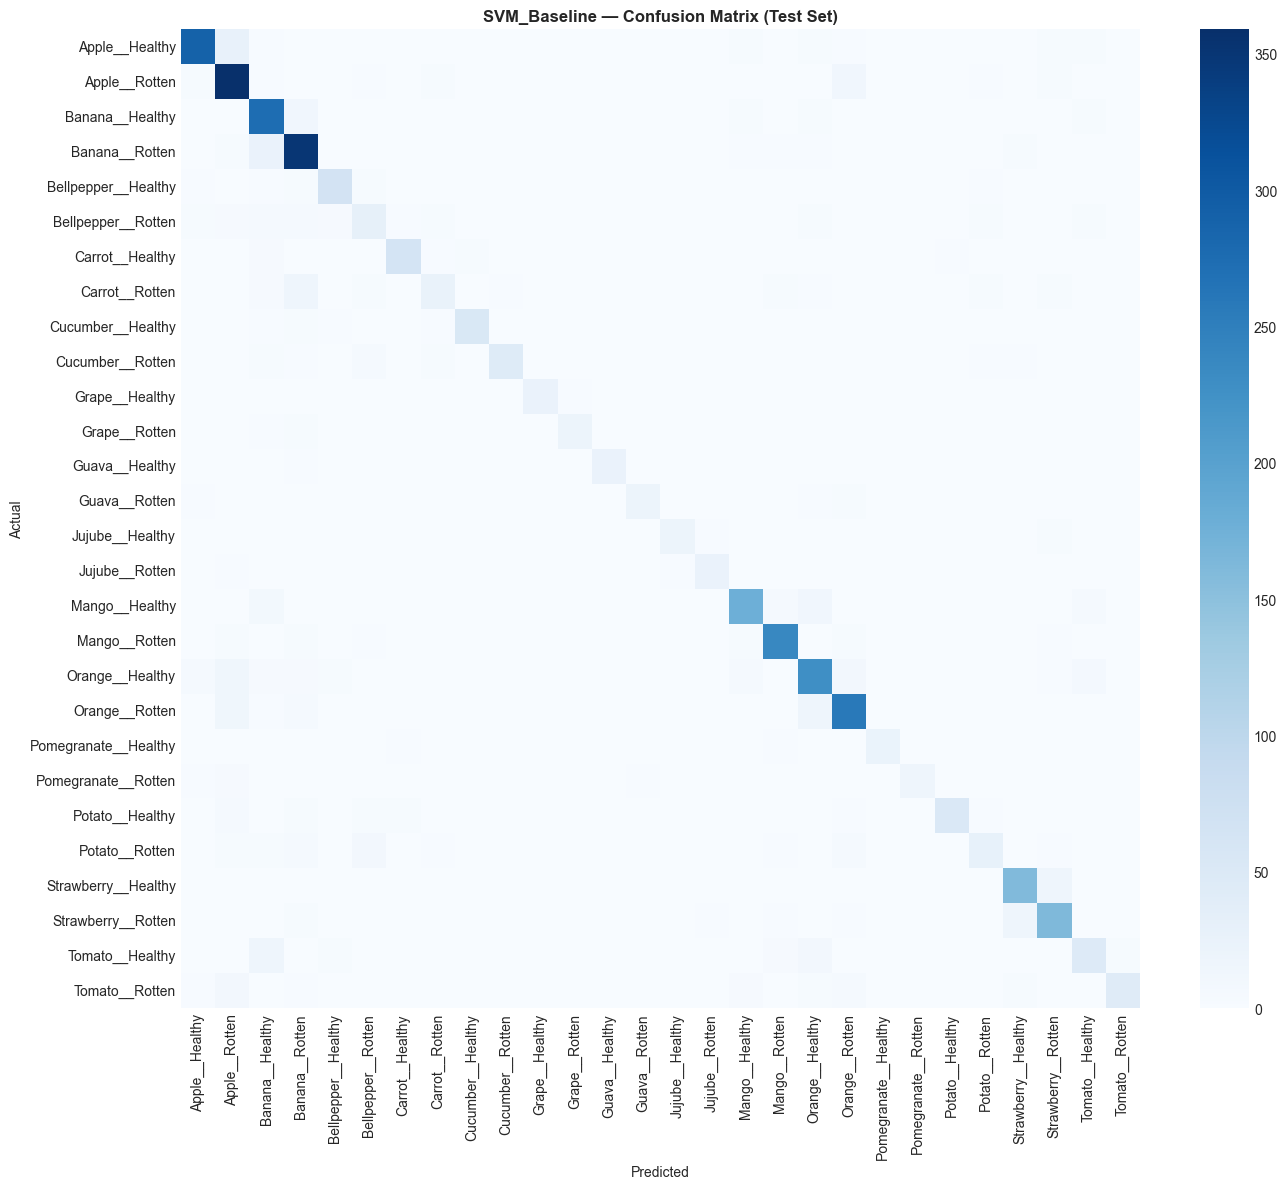

In [36]:
fig, ax = plt.subplots(
    figsize=(14, 12)
)

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    ax=ax
)

ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

ax.set_title(
    f"{best_name} — Confusion Matrix (Test Set)",
    fontweight="bold"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    "classical_baseline_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [37]:
cm_no_diag = cm.copy()

np.fill_diagonal(
    cm_no_diag,
    0
)

top_confusions = []

for i in range(len(classes)):

    for j in range(len(classes)):

        if cm_no_diag[i, j] > 0:

            top_confusions.append(
                (
                    classes[i],
                    classes[j],
                    cm_no_diag[i, j]
                )
            )


top_confusions = sorted(
    top_confusions,
    key=lambda x: x[2],
    reverse=True
)[:10]


print(
    "\nTop confused class pairs "
    "(true → predicted : count):"
)

for true_c, pred_c, count in top_confusions:

    print(
        f"  {true_c:30s} → "
        f"{pred_c:30s} : {count}"
    )


Top confused class pairs (true → predicted : count):
  Apple__Healthy                 → Apple__Rotten                  : 27
  Banana__Rotten                 → Banana__Healthy                : 24
  Strawberry__Healthy            → Strawberry__Rotten             : 18
  Carrot__Rotten                 → Banana__Rotten                 : 17
  Orange__Rotten                 → Orange__Healthy                : 17
  Strawberry__Rotten             → Strawberry__Healthy            : 17
  Tomato__Healthy                → Banana__Healthy                : 16
  Orange__Healthy                → Apple__Rotten                  : 15
  Orange__Rotten                 → Apple__Rotten                  : 15
  Apple__Rotten                  → Orange__Rotten                 : 13


In [38]:
os.makedirs(
    "metrics",
    exist_ok=True
)

with open(
    "metrics/classical_baseline_metrics.json",
    "w"
) as f:

    json.dump(
        best_metrics,
        f,
        indent=2
    )

print(
    f"[+] Metrics saved to "
    f"metrics/classical_baseline_metrics.json "
    f"(model: {best_name})"
)

print(
    "[+] Task 2 "
    "(Classical CV + Baseline) complete."
)

[+] Metrics saved to metrics/classical_baseline_metrics.json (model: SVM_Baseline)
[+] Task 2 (Classical CV + Baseline) complete.


## Shared Training & Evaluation Functions
Defines common training and evaluation utilities used by all deep learning models (Sections 3, 4, 5) to ensure the same two-stage strategy (Feature Extraction, then Full Fine-tuning) and the same evaluation metrics across models.

In [39]:
def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None
):

    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.set_grad_enabled(
        is_train
    ):

        for images, labels in loader:

            images = images.to(
                DEVICE
            )

            labels = labels.to(
                DEVICE
            )

            if is_train:
                optimizer.zero_grad()

            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )

            if is_train:

                loss.backward()

                optimizer.step()

            running_loss += (
                loss.item()
                * images.size(0)
            )

            preds = outputs.argmax(
                dim=1
            )

            correct += (
                preds == labels
            ).sum().item()

            total += labels.size(0)

    return (
        running_loss / total,
        correct / total
    )


def train_stage(
    model,
    loader_train,
    loader_val,
    criterion,
    optimizer,
    epochs,
    history,
    scheduler=None
):

    start = time.time()

    for epoch in range(
        1,
        epochs + 1
    ):

        train_loss, train_acc = run_epoch(
            model,
            loader_train,
            criterion,
            optimizer
        )

        val_loss, val_acc = run_epoch(
            model,
            loader_val,
            criterion
        )

        if scheduler is not None:
            scheduler.step(
                val_loss
            )

        history[
            "train_loss"
        ].append(train_loss)

        history[
            "train_acc"
        ].append(train_acc)

        history[
            "val_loss"
        ].append(val_loss)

        history[
            "val_acc"
        ].append(val_acc)

        print(
            f"Epoch {epoch}/{epochs} | "
            f"train_loss={train_loss:.4f} "
            f"train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} "
            f"val_acc={val_acc:.4f}"
        )

    elapsed = (
        time.time() - start
    )

    return elapsed

## Section 3 — Transfer Learning: AlexNet
Fine-tunes AlexNet (ImageNet weights) in two stages — feature extraction, then full fine-tuning with a 10x lower learning rate and `ReduceLROnPlateau` — evaluates on the test set, analyzes errors, and saves the results.

In [40]:
# Load fixed dataset splits
train_df = pd.read_csv("splits/train_df.csv")
val_df = pd.read_csv("splits/val_df.csv")
test_df = pd.read_csv("splits/test_df.csv")


# Load class-to-index mapping
with open("splits/class_to_idx.json") as f:
    class_to_idx = json.load(f)


# Load shared augmentation configuration
with open("splits/augmentation_config.json") as f:
    aug_config = json.load(f)


# Class information
classes = sorted(
    class_to_idx,
    key=class_to_idx.get
)

NUM_CLASSES = len(classes)


# Shared augmentation settings
MINORITY_FRUITS = set(
    aug_config["minority_fruits"]
)

ROUND_SYMMETRIC_FRUITS = set(
    aug_config["round_symmetric_fruits"]
)

STANDARD_AUG = aug_config[
    "standard_augmentation"
]

MINORITY_AUG = aug_config[
    "minority_augmentation"
]


print(
    f"[+] Train: {len(train_df):,}"
)

print(
    f"[+] Val:   {len(val_df):,}"
)

print(
    f"[+] Test:  {len(test_df):,}"
)

print(
    f"[+] Number of classes: {NUM_CLASSES}"
)

print(
    f"[+] Minority fruits: "
    f"{sorted(MINORITY_FRUITS)}"
)

print(
    f"[+] Round/symmetric fruits: "
    f"{sorted(ROUND_SYMMETRIC_FRUITS)}"
)

[+] Train: 18,107
[+] Val:   3,880
[+] Test:  3,881
[+] Number of classes: 28
[+] Minority fruits: ['Grape', 'Guava', 'Jujube', 'Pomegranate']
[+] Round/symmetric fruits: ['Apple', 'Grape', 'Guava', 'Orange', 'Pomegranate', 'Tomato']


In [41]:
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


def build_train_transform(
    aug_cfg,
    fruit_name
):
    """
    Build the class-aware augmentation pipeline
    defined in Task 1.
    """

    ops = [
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(
            p=aug_cfg.get(
                "horizontal_flip_p",
                0.5
            )
        )
    ]

    # Vertical flip for round/symmetric fruits
    if fruit_name in ROUND_SYMMETRIC_FRUITS:

        ops.append(
            transforms.RandomVerticalFlip(
                p=aug_cfg.get(
                    "vertical_flip_p",
                    0.3
                )
            )
        )

    # Rotation
    rotation_degrees = aug_cfg.get(
        "rotation_degrees",
        15
    )

    ops.append(
        transforms.RandomRotation(
            degrees=rotation_degrees
        )
    )

    # Minority-class augmentation
    if fruit_name in MINORITY_FRUITS:

        color_cfg = aug_cfg.get(
            "color_jitter",
            {}
        )

        ops.append(
            transforms.ColorJitter(
                brightness=color_cfg.get(
                    "brightness",
                    0.3
                ),
                contrast=color_cfg.get(
                    "contrast",
                    0.3
                ),
                saturation=color_cfg.get(
                    "saturation",
                    0.3
                ),
                hue=color_cfg.get(
                    "hue",
                    0.1
                )
            )
        )

        affine_cfg = aug_cfg.get(
            "random_affine",
            {}
        )

        ops.append(
            transforms.RandomAffine(
                degrees=0,
                translate=tuple(
                    affine_cfg.get(
                        "translate",
                        [0.1, 0.1]
                    )
                ),
                scale=tuple(
                    affine_cfg.get(
                        "scale",
                        [0.85, 1.15]
                    )
                )
            )
        )

    # Convert to tensor + ImageNet normalization
    ops.extend([
        transforms.ToTensor(),
        transforms.Normalize(
            IMAGENET_MEAN,
            IMAGENET_STD
        )
    ])

    return transforms.Compose(ops)


# Get the actual fruit names from the dataset
fruit_types = sorted(
    train_df["fruit"].unique()
)

print(
    "[+] Fruit types found:",
    fruit_types
)

print(
    "[+] Number of fruit types:",
    len(fruit_types)
)


# Build transforms using actual fruit names
standard_transforms = {
    fruit: build_train_transform(
        STANDARD_AUG,
        fruit
    )
    for fruit in fruit_types
    if fruit not in MINORITY_FRUITS
}


minority_transforms = {
    fruit: build_train_transform(
        MINORITY_AUG,
        fruit
    )
    for fruit in fruit_types
    if fruit in MINORITY_FRUITS
}


print(
    "[+] Standard transforms:",
    len(standard_transforms)
)

print(
    "[+] Minority transforms:",
    len(minority_transforms)
)


# Evaluation transform
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


class FreshnessDataset(Dataset):
    """
    Dataset using the class-aware augmentation
    strategy defined in Task 1.
    """

    def __init__(
        self,
        df,
        class_to_idx,
        minority_fruits,
        is_train=False
    ):

        df = df.copy()

        # Optional minority oversampling
        if is_train:

            oversample_factor = MINORITY_AUG.get(
                "oversample_factor",
                1
            )

            minority_rows = df[
                df["fruit"].isin(minority_fruits)
            ]

            if oversample_factor > 1:

                df = pd.concat(
                    [df] +
                    [minority_rows] *
                    (oversample_factor - 1),
                    ignore_index=True
                )

        self.filepaths = df[
            "filepath"
        ].values

        self.fruits = df[
            "fruit"
        ].values

        self.labels = (
            df["class_label"]
            .map(class_to_idx)
            .values
        )

        self.is_train = is_train

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):

        img = Image.open(
            self.filepaths[idx]
        ).convert("RGB")

        fruit = self.fruits[idx]

        if self.is_train:

            if fruit in MINORITY_FRUITS:

                transform = minority_transforms[
                    fruit
                ]

            else:

                transform = standard_transforms[
                    fruit
                ]

        else:

            transform = eval_transform

        img = transform(img)

        label = self.labels[idx]

        return img, label


# Create datasets
train_ds = FreshnessDataset(
    train_df,
    class_to_idx,
    MINORITY_FRUITS,
    is_train=True
)

val_ds = FreshnessDataset(
    val_df,
    class_to_idx,
    MINORITY_FRUITS,
    is_train=False
)

test_ds = FreshnessDataset(
    test_df,
    class_to_idx,
    MINORITY_FRUITS,
    is_train=False
)


# DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)


print(
    f"[+] Train samples: "
    f"{len(train_ds):,}"
)

print(
    f"[+] Train batches: "
    f"{len(train_loader)}"
)

print(
    f"[+] Val batches: "
    f"{len(val_loader)}"
)

print(
    f"[+] Test batches: "
    f"{len(test_loader)}"
)

[+] Fruit types found: ['Apple', 'Banana', 'Bellpepper', 'Carrot', 'Cucumber', 'Grape', 'Guava', 'Jujube', 'Mango', 'Orange', 'Pomegranate', 'Potato', 'Strawberry', 'Tomato']
[+] Number of fruit types: 14
[+] Standard transforms: 10
[+] Minority transforms: 4
[+] Train samples: 18,107
[+] Train batches: 566
[+] Val batches: 122
[+] Test batches: 122


In [42]:
def build_alexnet(num_classes):

    model = models.alexnet(
        weights=models.AlexNet_Weights.IMAGENET1K_V1
    )

    in_features = (
        model.classifier[6].in_features
    )

    model.classifier[6] = nn.Linear(
        in_features,
        num_classes
    )

    return model


model = build_alexnet(
    NUM_CLASSES
).to(DEVICE)


# Parameter counts
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


print(
    f"[+] Total parameters: "
    f"{total_params:,}"
)

print(
    f"[+] Trainable parameters: "
    f"{trainable_params:,}"
)

[+] Total parameters: 57,118,556
[+] Trainable parameters: 57,118,556


In [43]:
metrics_log = new_metrics_log("AlexNet")
metrics_log["num_params_total"] = total_params


In [ ]:
# Freeze the entire network
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the new classification head
for param in model.classifier[6].parameters():
    param.requires_grad = True

trainable_stage1 = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

metrics_log["num_params_trainable_stage1"] = trainable_stage1

print(
    f"[+] Trainable parameters in Stage 1: "
    f"{trainable_stage1:,}"
)

print(
    f"[+] Percentage of total: "
    f"{trainable_stage1 / total_params * 100:.2f}%"
)

criterion = nn.CrossEntropyLoss()

optimizer_stage1 = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-3
)

STAGE1_EPOCHS = 5

stage1_time = train_stage(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer_stage1,
    epochs=STAGE1_EPOCHS,
    history=metrics_log["stage1_history"]
)

metrics_log["stage1_training_time_sec"] = stage1_time

print(
    f"[+] Stage 1 completed in "
    f"{stage1_time:.1f}s"
)

print(
    f"[+] Average time per epoch: "
    f"{stage1_time / STAGE1_EPOCHS:.1f}s"
)

[+] Trainable parameters in Stage 1: 114,716
[+] Percentage of total: 0.20%


In [ ]:
 # Unfreeze the entire network
for param in model.parameters():
    param.requires_grad = True


trainable_stage2 = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

metrics_log[
    "num_params_trainable_stage2"
] = trainable_stage2


print(
    f"[+] Trainable parameters in Stage 2: "
    f"{trainable_stage2:,}"
)

print(
    f"[+] Percentage of total: "
    f"{trainable_stage2 / total_params * 100:.2f}%"
)


optimizer_stage2 = optim.Adam(
    model.parameters(),
    lr=1e-4
)


scheduler_stage2 = (
    optim.lr_scheduler.ReduceLROnPlateau(
        optimizer_stage2,
        mode="min",
        factor=0.5,
        patience=2
    )
)


STAGE2_EPOCHS = 10


stage2_time = train_stage(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer_stage2,
    epochs=STAGE2_EPOCHS,
    history=metrics_log[
        "stage2_history"
    ],
    scheduler=scheduler_stage2
)


metrics_log[
    "stage2_training_time_sec"
] = stage2_time


print(
    f"[+] Stage 2 completed in "
    f"{stage2_time:.1f}s"
)

print(
    f"[+] Average time per epoch: "
    f"{stage2_time / STAGE2_EPOCHS:.1f}s"
)


# Save final model
os.makedirs(
    "models",
    exist_ok=True
)

torch.save(
    model.state_dict(),
    "models/alexnet_finetuned.pth"
)

print(
    "[+] Model weights saved to "
    "models/alexnet_finetuned.pth"
)

[+] Trainable parameters in Stage 2: 57,118,556
[+] Percentage of total: 100.00%


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/10 | train_loss=0.3061 train_acc=0.9069 | val_loss=0.2546 val_acc=0.9224


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 2/10 | train_loss=0.1957 train_acc=0.9363 | val_loss=0.1846 val_acc=0.9436


...

Epoch 8/10 | train_loss=0.0442 train_acc=0.9852 | val_loss=0.1317 val_acc=0.9686


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 9/10 | train_loss=0.0446 train_acc=0.9861 | val_loss=0.1377 val_acc=0.9698


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 10/10 | train_loss=0.0369 train_acc=0.9877 | val_loss=0.1715 val_acc=0.9611
[+] Stage 2 completed in 2501.9s
[+] Average time per epoch: 250.2s
[+] Model weights saved to models/alexnet_finetuned.pth


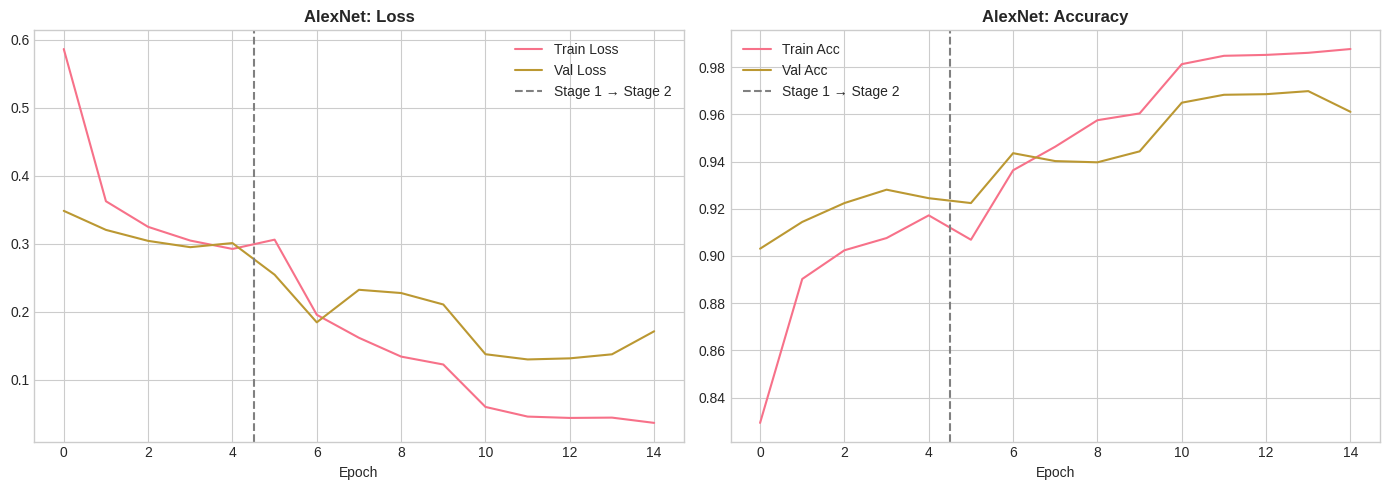

In [ ]:
def plot_training_curves(
    metrics_log,
    model_name
):

    h1 = metrics_log[
        "stage1_history"
    ]

    h2 = metrics_log[
        "stage2_history"
    ]


    train_loss = (
        h1["train_loss"]
        + h2["train_loss"]
    )

    val_loss = (
        h1["val_loss"]
        + h2["val_loss"]
    )

    train_acc = (
        h1["train_acc"]
        + h2["train_acc"]
    )

    val_acc = (
        h1["val_acc"]
        + h2["val_acc"]
    )


    split_epoch = len(
        h1["train_loss"]
    )


    fig, axes = plt.subplots(
        1,
        2,
        figsize=(14, 5)
    )


    # Loss
    axes[0].plot(
        train_loss,
        label="Train Loss"
    )

    axes[0].plot(
        val_loss,
        label="Val Loss"
    )

    axes[0].axvline(
        split_epoch - 0.5,
        color="gray",
        linestyle="--",
        label="Stage 1 → Stage 2"
    )

    axes[0].set_title(
        f"{model_name}: Loss",
        fontweight="bold"
    )

    axes[0].set_xlabel(
        "Epoch"
    )

    axes[0].legend()


    # Accuracy
    axes[1].plot(
        train_acc,
        label="Train Acc"
    )

    axes[1].plot(
        val_acc,
        label="Val Acc"
    )

    axes[1].axvline(
        split_epoch - 0.5,
        color="gray",
        linestyle="--",
        label="Stage 1 → Stage 2"
    )

    axes[1].set_title(
        f"{model_name}: Accuracy",
        fontweight="bold"
    )

    axes[1].set_xlabel(
        "Epoch"
    )

    axes[1].legend()


    plt.tight_layout()

    plt.savefig(
        f"{model_name.lower()}_training_curves.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


plot_training_curves(
    metrics_log,
    "AlexNet"
)

In [ ]:
  model.eval()

all_preds = []
all_labels = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            DEVICE
        )

        outputs = model(
            images
        )

        preds = (
            outputs
            .argmax(dim=1)
            .cpu()
            .numpy()
        )

        all_preds.extend(
            preds
        )

        all_labels.extend(
            labels.numpy()
        )


# Calculate test metrics
test_acc = accuracy_score(
    all_labels,
    all_preds
)


precision, recall, f1, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )
)


metrics_log[
    "test_accuracy"
] = test_acc

metrics_log[
    "test_precision_macro"
] = precision

metrics_log[
    "test_recall_macro"
] = recall

metrics_log[
    "test_f1_macro"
] = f1


metrics_log[
    "classification_report"
] = classification_report(
    all_labels,
    all_preds,
    target_names=classes,
    zero_division=0,
    output_dict=True
)


print(
    f"[+] Test Accuracy: "
    f"{test_acc * 100:.2f}%"
)

print(
    f"[+] Test Precision (macro): "
    f"{precision:.4f}"
)

print(
    f"[+] Test Recall (macro): "
    f"{recall:.4f}"
)

print(
    f"[+] Test F1 (macro): "
    f"{f1:.4f}"
)


# --------------------------------
# Inference speed benchmark
# --------------------------------

sample_batch, _ = next(
    iter(test_loader)
)

sample_image = sample_batch[
    :1
].to(DEVICE)


# Warm-up
with torch.no_grad():

    for _ in range(5):

        _ = model(
            sample_image
        )


# Synchronize GPU before timing
if DEVICE.type == "cuda":
    torch.cuda.synchronize()


n_runs = 100

start = time.time()


with torch.no_grad():

    for _ in range(n_runs):

        _ = model(
            sample_image
        )


if DEVICE.type == "cuda":
    torch.cuda.synchronize()


elapsed = (
    time.time() - start
)


inference_ms = (
    elapsed / n_runs
) * 1000


metrics_log[
    "inference_time_ms_per_image"
] = inference_ms


print(
    f"[+] Inference time: "
    f"{inference_ms:.2f} ms/image"
)

[+] Test Accuracy: 95.88%
[+] Test Precision (macro): 0.9182
[+] Test Recall (macro): 0.9279
[+] Test F1 (macro): 0.9216
[+] Inference time: 2.11 ms/image


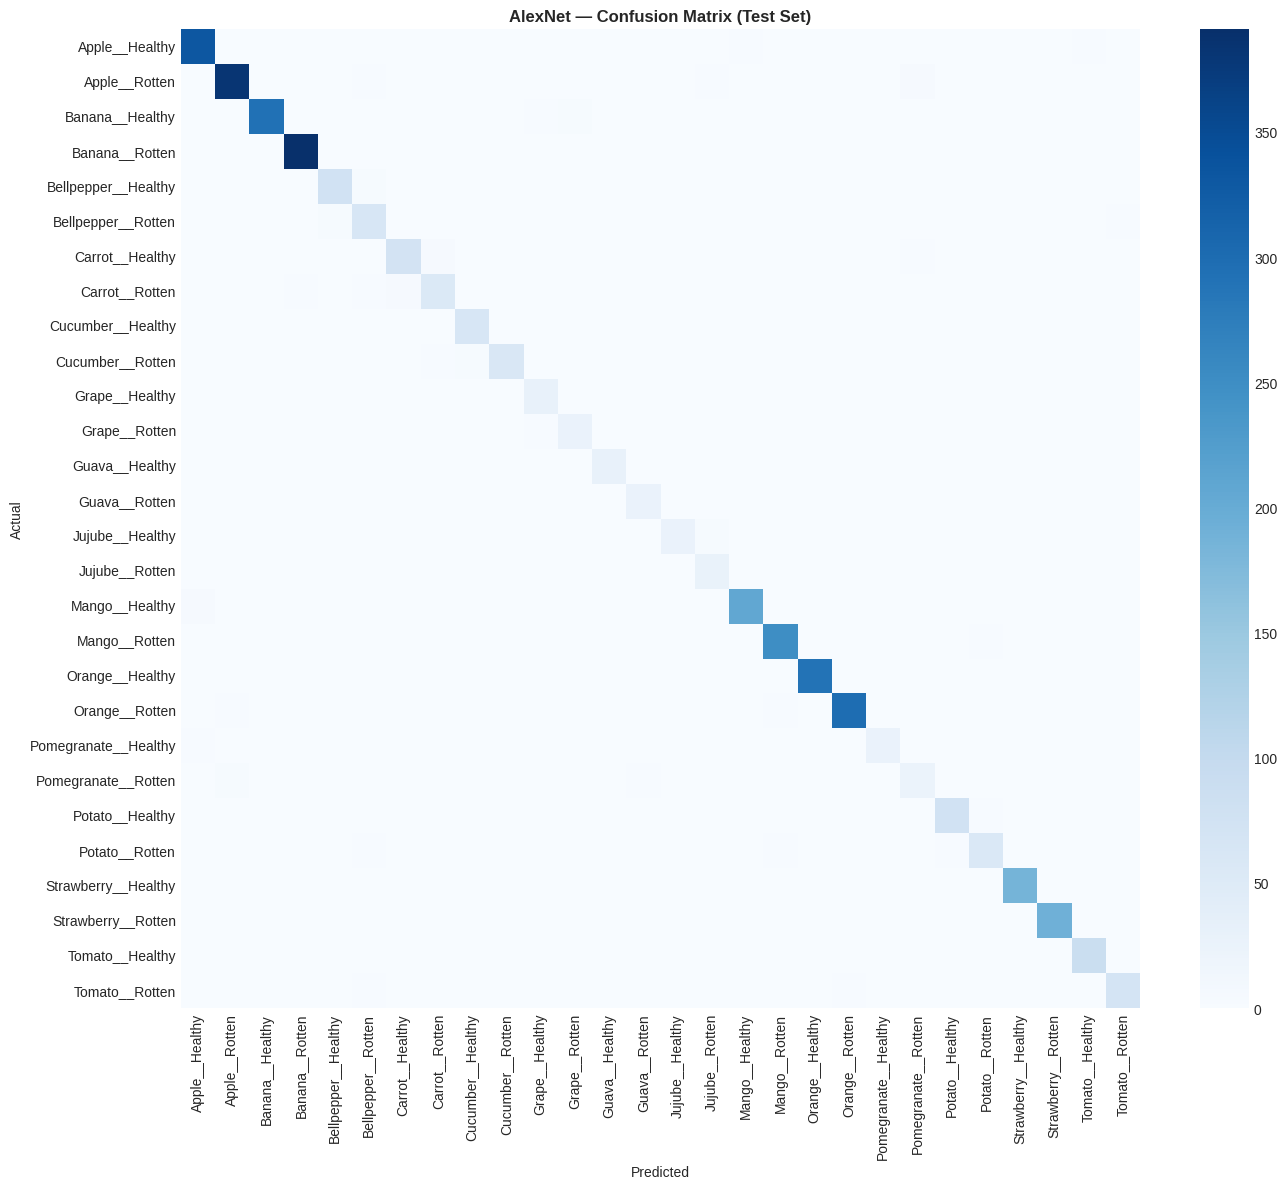


Top confused class pairs (true → predicted : count):
  Carrot__Healthy                → Carrot__Rotten                 : 6
  Mango__Healthy                 → Apple__Healthy                 : 6
  Apple__Rotten                  → Pomegranate__Rotten            : 5
  Carrot__Rotten                 → Carrot__Healthy                : 5
  Banana__Healthy                → Grape__Rotten                  : 4
  Bellpepper__Healthy            → Bellpepper__Rotten             : 4
  Bellpepper__Rotten             → Bellpepper__Healthy            : 4
  Cucumber__Rotten               → Cucumber__Healthy              : 4
  Jujube__Healthy                → Jujube__Rotten                 : 4
  Pomegranate__Rotten            → Apple__Rotten                  : 4

[+] Per-class F1 for minority fruits:
  Grape__Healthy                 F1=0.896 support=30.0
  Grape__Rotten                  F1=0.831 support=30.0
  Guava__Healthy                 F1=1.000 support=30.0
  Guava__Rotten                  F1=0.900 

In [ ]:
# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_preds
)


metrics_log[
    "confusion_matrix"
] = cm.tolist()


fig, ax = plt.subplots(
    figsize=(14, 12)
)


sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    ax=ax
)


ax.set_xlabel(
    "Predicted"
)

ax.set_ylabel(
    "Actual"
)

ax.set_title(
    "AlexNet — Confusion Matrix (Test Set)",
    fontweight="bold"
)


plt.xticks(
    rotation=90
)

plt.yticks(
    rotation=0
)

plt.tight_layout()


plt.savefig(
    "alexnet_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# --------------------------------
# Top confusion pairs
# --------------------------------

cm_no_diag = cm.copy()

np.fill_diagonal(
    cm_no_diag,
    0
)


top_confusions = []


for i in range(
    len(classes)
):

    for j in range(
        len(classes)
    ):

        if cm_no_diag[i, j] > 0:

            top_confusions.append(
                (
                    classes[i],
                    classes[j],
                    cm_no_diag[i, j]
                )
            )


top_confusions = sorted(
    top_confusions,
    key=lambda x: x[2],
    reverse=True
)[:10]


print(
    "\nTop confused class pairs "
    "(true → predicted : count):"
)


for true_c, pred_c, count in top_confusions:

    print(
        f"  {true_c:30s} → "
        f"{pred_c:30s} : {count}"
    )


# --------------------------------
# Minority-class analysis
# --------------------------------

minority_class_labels = [
    c
    for c in classes
    if c.split("__")[0]
    in MINORITY_FRUITS
]


minority_report = {
    c: metrics_log[
        "classification_report"
    ][c]

    for c in minority_class_labels

    if c in metrics_log[
        "classification_report"
    ]
}


print(
    "\n[+] Per-class F1 for minority fruits:"
)


for c, stats in minority_report.items():

    print(
        f"  {c:30s} "
        f"F1={stats['f1-score']:.3f} "
        f"support={stats['support']}"
    )

In [ ]:
# Calculate total training time
total_training_time = (
    metrics_log[
        "stage1_training_time_sec"
    ]
    +
    metrics_log[
        "stage2_training_time_sec"
    ]
)


metrics_log[
    "total_training_time_sec"
] = total_training_time


# Create metrics directory
os.makedirs(
    "metrics",
    exist_ok=True
)


# Save metrics
with open(
    "metrics/alexnet_metrics.json",
    "w"
) as f:

    json.dump(
        metrics_log,
        f,
        indent=2
    )


print(
    "[+] AlexNet metrics saved to "
    "metrics/alexnet_metrics.json"
)

print(
    f"[+] Total training time: "
    f"{total_training_time:.1f}s"
)

[+] AlexNet metrics saved to metrics/alexnet_metrics.json
[+] Total training time: 3723.3s


## Section 4 — Transfer Learning: ResNet50
Applies the exact same methodology as Section 3 (same shared functions, same two-stage strategy) using ResNet50 (ImageNet weights) instead of AlexNet, to keep the comparison in Section 6 fair.

In [ ]:
# Load fixed dataset splits
train_df = pd.read_csv("splits/train_df.csv")
val_df = pd.read_csv("splits/val_df.csv")
test_df = pd.read_csv("splits/test_df.csv")


# Load class-to-index mapping
with open("splits/class_to_idx.json") as f:
    class_to_idx = json.load(f)


# Load shared augmentation configuration
with open("splits/augmentation_config.json") as f:
    aug_config = json.load(f)


# Class information
classes = sorted(
    class_to_idx,
    key=class_to_idx.get
)

NUM_CLASSES = len(classes)


# Shared augmentation settings
MINORITY_FRUITS = set(
    aug_config["minority_fruits"]
)

ROUND_SYMMETRIC_FRUITS = set(
    aug_config["round_symmetric_fruits"]
)

STANDARD_AUG = aug_config[
    "standard_augmentation"
]

MINORITY_AUG = aug_config[
    "minority_augmentation"
]


print(
    f"[+] Train: {len(train_df):,}"
)

print(
    f"[+] Val:   {len(val_df):,}"
)

print(
    f"[+] Test:  {len(test_df):,}"
)

print(
    f"[+] Number of classes: {NUM_CLASSES}"
)

print(
    f"[+] Minority fruits: "
    f"{sorted(MINORITY_FRUITS)}"
)

print(
    f"[+] Round/symmetric fruits: "
    f"{sorted(ROUND_SYMMETRIC_FRUITS)}"
)

[+] Train: 18,107
[+] Val:   3,880
[+] Test:  3,881
[+] Number of classes: 28
[+] Minority fruits: ['Grape', 'Guava', 'Jujube', 'Pomegranate']
[+] Round/symmetric fruits: ['Apple', 'Grape', 'Guava', 'Orange', 'Pomegranate', 'Tomato']


In [ ]:
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


def build_train_transform(
    aug_cfg,
    fruit_name
):
    """
    Build the class-aware augmentation pipeline
    defined in Task 1.
    """

    ops = [
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(
            p=aug_cfg.get(
                "horizontal_flip_p",
                0.5
            )
        )
    ]

    # Vertical flip for round/symmetric fruits
    if fruit_name in ROUND_SYMMETRIC_FRUITS:

        ops.append(
            transforms.RandomVerticalFlip(
                p=aug_cfg.get(
                    "vertical_flip_p",
                    0.3
                )
            )
        )

    # Rotation
    rotation_degrees = aug_cfg.get(
        "rotation_degrees",
        15
    )

    ops.append(
        transforms.RandomRotation(
            degrees=rotation_degrees
        )
    )

    # Minority-class augmentation
    if fruit_name in MINORITY_FRUITS:

        color_cfg = aug_cfg.get(
            "color_jitter",
            {}
        )

        ops.append(
            transforms.ColorJitter(
                brightness=color_cfg.get(
                    "brightness",
                    0.3
                ),
                contrast=color_cfg.get(
                    "contrast",
                    0.3
                ),
                saturation=color_cfg.get(
                    "saturation",
                    0.3
                ),
                hue=color_cfg.get(
                    "hue",
                    0.1
                )
            )
        )

        affine_cfg = aug_cfg.get(
            "random_affine",
            {}
        )

        ops.append(
            transforms.RandomAffine(
                degrees=0,
                translate=tuple(
                    affine_cfg.get(
                        "translate",
                        [0.1, 0.1]
                    )
                ),
                scale=tuple(
                    affine_cfg.get(
                        "scale",
                        [0.85, 1.15]
                    )
                )
            )
        )

    # Convert to tensor + ImageNet normalization
    ops.extend([
        transforms.ToTensor(),
        transforms.Normalize(
            IMAGENET_MEAN,
            IMAGENET_STD
        )
    ])

    return transforms.Compose(ops)


# Get the actual fruit names from the dataset
fruit_types = sorted(
    train_df["fruit"].unique()
)

print(
    "[+] Fruit types found:",
    fruit_types
)

print(
    "[+] Number of fruit types:",
    len(fruit_types)
)


# Build transforms using actual fruit names
standard_transforms = {
    fruit: build_train_transform(
        STANDARD_AUG,
        fruit
    )
    for fruit in fruit_types
    if fruit not in MINORITY_FRUITS
}


minority_transforms = {
    fruit: build_train_transform(
        MINORITY_AUG,
        fruit
    )
    for fruit in fruit_types
    if fruit in MINORITY_FRUITS
}


print(
    "[+] Standard transforms:",
    len(standard_transforms)
)

print(
    "[+] Minority transforms:",
    len(minority_transforms)
)


# Evaluation transform
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


class FreshnessDataset(Dataset):
    """
    Dataset using the class-aware augmentation
    strategy defined in Task 1.
    """

    def __init__(
        self,
        df,
        class_to_idx,
        minority_fruits,
        is_train=False
    ):

        df = df.copy()

        # Optional minority oversampling
        if is_train:

            oversample_factor = MINORITY_AUG.get(
                "oversample_factor",
                1
            )

            minority_rows = df[
                df["fruit"].isin(minority_fruits)
            ]

            if oversample_factor > 1:

                df = pd.concat(
                    [df] +
                    [minority_rows] *
                    (oversample_factor - 1),
                    ignore_index=True
                )

        self.filepaths = df[
            "filepath"
        ].values

        self.fruits = df[
            "fruit"
        ].values

        self.labels = (
            df["class_label"]
            .map(class_to_idx)
            .values
        )

        self.is_train = is_train

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):

        img = Image.open(
            self.filepaths[idx]
        ).convert("RGB")

        fruit = self.fruits[idx]

        if self.is_train:

            if fruit in MINORITY_FRUITS:

                transform = minority_transforms[
                    fruit
                ]

            else:

                transform = standard_transforms[
                    fruit
                ]

        else:

            transform = eval_transform

        img = transform(img)

        label = self.labels[idx]

        return img, label


# Create datasets
train_ds = FreshnessDataset(
    train_df,
    class_to_idx,
    MINORITY_FRUITS,
    is_train=True
)

val_ds = FreshnessDataset(
    val_df,
    class_to_idx,
    MINORITY_FRUITS,
    is_train=False
)

test_ds = FreshnessDataset(
    test_df,
    class_to_idx,
    MINORITY_FRUITS,
    is_train=False
)


# DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)


print(
    f"[+] Train samples: "
    f"{len(train_ds):,}"
)

print(
    f"[+] Train batches: "
    f"{len(train_loader)}"
)

print(
    f"[+] Val batches: "
    f"{len(val_loader)}"
)

print(
    f"[+] Test batches: "
    f"{len(test_loader)}"
)

[+] Fruit types found: ['Apple', 'Banana', 'Bellpepper', 'Carrot', 'Cucumber', 'Grape', 'Guava', 'Jujube', 'Mango', 'Orange', 'Pomegranate', 'Potato', 'Strawberry', 'Tomato']
[+] Number of fruit types: 14
[+] Standard transforms: 10
[+] Minority transforms: 4
[+] Train samples: 18,107
[+] Train batches: 566
[+] Val batches: 122
[+] Test batches: 122


In [ ]:
def build_resnet50(num_classes):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

model = build_resnet50(NUM_CLASSES).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[+] Total parameters: {total_params:,}")
print(f"[+] Trainable parameters: {trainable_params:,}")


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 166MB/s]


[+] Total parameters: 23,565,404
[+] Trainable parameters: 23,565,404


In [ ]:
metrics_log = new_metrics_log("ResNet50")
metrics_log["num_params_total"] = total_params


In [ ]:
# ---- Stage 1: Feature Extraction (Backbone Frozen) ----
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the new classification head (fc)
for param in model.fc.parameters():
    param.requires_grad = True

trainable_stage1 = sum(p.numel() for p in model.parameters() if p.requires_grad)
metrics_log["num_params_trainable_stage1"] = trainable_stage1

print(f"[+] Trainable parameters in Stage 1: {trainable_stage1:,}")
print(f"[+] Percentage of total: {trainable_stage1 / total_params * 100:.2f}%")

criterion = nn.CrossEntropyLoss()
optimizer_stage1 = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
STAGE1_EPOCHS = 5

stage1_time = train_stage(
    model, train_loader, val_loader, criterion, optimizer_stage1,
    epochs=STAGE1_EPOCHS, history=metrics_log["stage1_history"]
)
metrics_log["stage1_training_time_sec"] = stage1_time
print(f"[+] Stage 1 completed in {stage1_time:.1f}s")
print(f"[+] Average time per epoch: {stage1_time / STAGE1_EPOCHS:.1f}s")


[+] Trainable parameters in Stage 1: 57,372
[+] Percentage of total: 0.24%


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/5 | train_loss=0.8396 train_acc=0.8163 | val_loss=0.3687 val_acc=0.9131


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 2/5 | train_loss=0.2957 train_acc=0.9310 | val_loss=0.2486 val_acc=0.9379


...

Epoch 3/5 | train_loss=0.2084 train_acc=0.9501 | val_loss=0.2083 val_acc=0.9428


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 4/5 | train_loss=0.1579 train_acc=0.9635 | val_loss=0.1768 val_acc=0.9490


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 5/5 | train_loss=0.1368 train_acc=0.9655 | val_loss=0.1553 val_acc=0.9536
[+] Stage 1 completed in 1342.7s
[+] Average time per epoch: 268.5s


In [ ]:
# ---- Stage 2: Full Fine-tuning (Backbone Unfrozen) ----
for param in model.parameters():
    param.requires_grad = True

trainable_stage2 = sum(p.numel() for p in model.parameters() if p.requires_grad)
metrics_log["num_params_trainable_stage2"] = trainable_stage2

print(f"[+] Trainable parameters in Stage 2: {trainable_stage2:,}")
print(f"[+] Percentage of total: {trainable_stage2 / total_params * 100:.2f}%")

optimizer_stage2 = optim.Adam(model.parameters(), lr=1e-4)
scheduler_stage2 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage2, mode="min", factor=0.5, patience=2
)
STAGE2_EPOCHS = 10

stage2_time = train_stage(
    model, train_loader, val_loader, criterion, optimizer_stage2,
    epochs=STAGE2_EPOCHS, history=metrics_log["stage2_history"], scheduler=scheduler_stage2
)
metrics_log["stage2_training_time_sec"] = stage2_time
print(f"[+] Stage 2 completed in {stage2_time:.1f}s")

os.makedirs("models", exist_ok=True)
torch.save(model.state_dict(), "models/resnet50_finetuned.pth")
print("[+] Model weights saved to models/resnet50_finetuned.pth")


[+] Trainable parameters in Stage 2: 23,565,404
[+] Percentage of total: 100.00%


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/10 | train_loss=0.0791 train_acc=0.9746 | val_loss=0.0833 val_acc=0.9750


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 2/10 | train_loss=0.0368 train_acc=0.9884 | val_loss=0.0694 val_acc=0.9807


...

Epoch 8/10 | train_loss=0.0068 train_acc=0.9980 | val_loss=0.0554 val_acc=0.9863


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 9/10 | train_loss=0.0031 train_acc=0.9993 | val_loss=0.0598 val_acc=0.9853


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 10/10 | train_loss=0.0034 train_acc=0.9990 | val_loss=0.0672 val_acc=0.9830
[+] Stage 2 completed in 2941.5s
[+] Model weights saved to models/resnet50_finetuned.pth


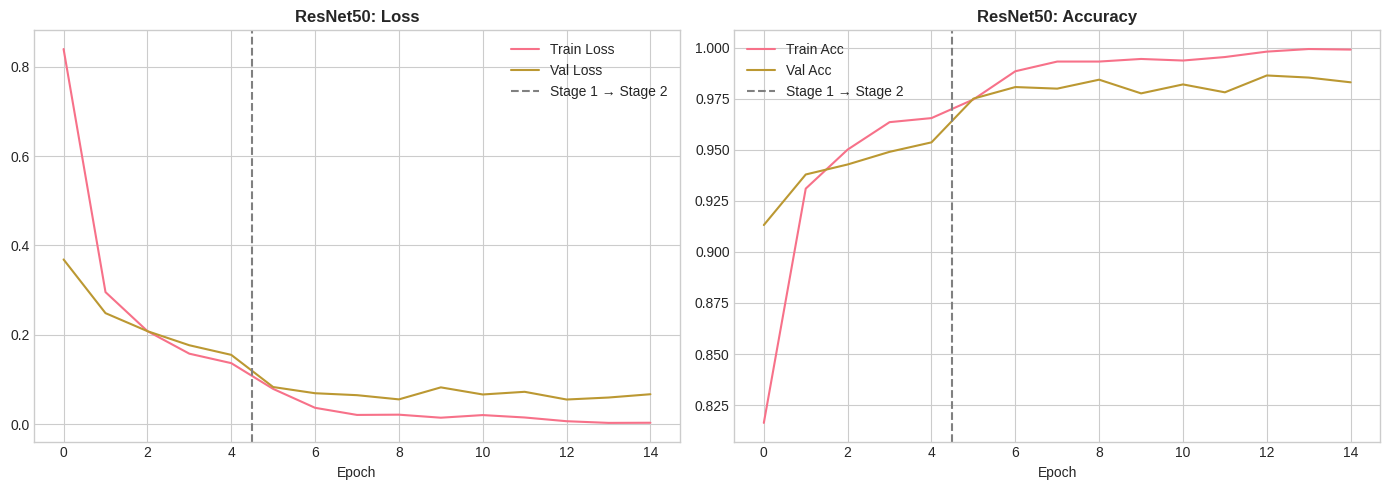

In [ ]:
plot_training_curves(metrics_log, "ResNet50")


In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

test_acc = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="macro", zero_division=0
)

metrics_log["test_accuracy"] = test_acc
metrics_log["test_precision_macro"] = precision
metrics_log["test_recall_macro"] = recall
metrics_log["test_f1_macro"] = f1
metrics_log["classification_report"] = classification_report(
    all_labels, all_preds, target_names=classes, zero_division=0, output_dict=True
)

print(f"[+] Test Accuracy: {test_acc * 100:.2f}%")
print(f"[+] Test Precision (macro): {precision:.4f}")
print(f"[+] Test Recall (macro): {recall:.4f}")
print(f"[+] Test F1 (macro): {f1:.4f}")

# ---- Inference speed benchmark ----
sample_batch, _ = next(iter(test_loader))
sample_image = sample_batch[:1].to(DEVICE)

with torch.no_grad():
    for _ in range(5):
        _ = model(sample_image)

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

n_runs = 100
start = time.time()
with torch.no_grad():
    for _ in range(n_runs):
        _ = model(sample_image)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

inference_ms = (time.time() - start) / n_runs * 1000
metrics_log["inference_time_ms_per_image"] = inference_ms
print(f"[+] Inference time: {inference_ms:.2f} ms/image")


[+] Test Accuracy: 98.38%
[+] Test Precision (macro): 0.9786
[+] Test Recall (macro): 0.9630
[+] Test F1 (macro): 0.9693
[+] Inference time: 5.96 ms/image


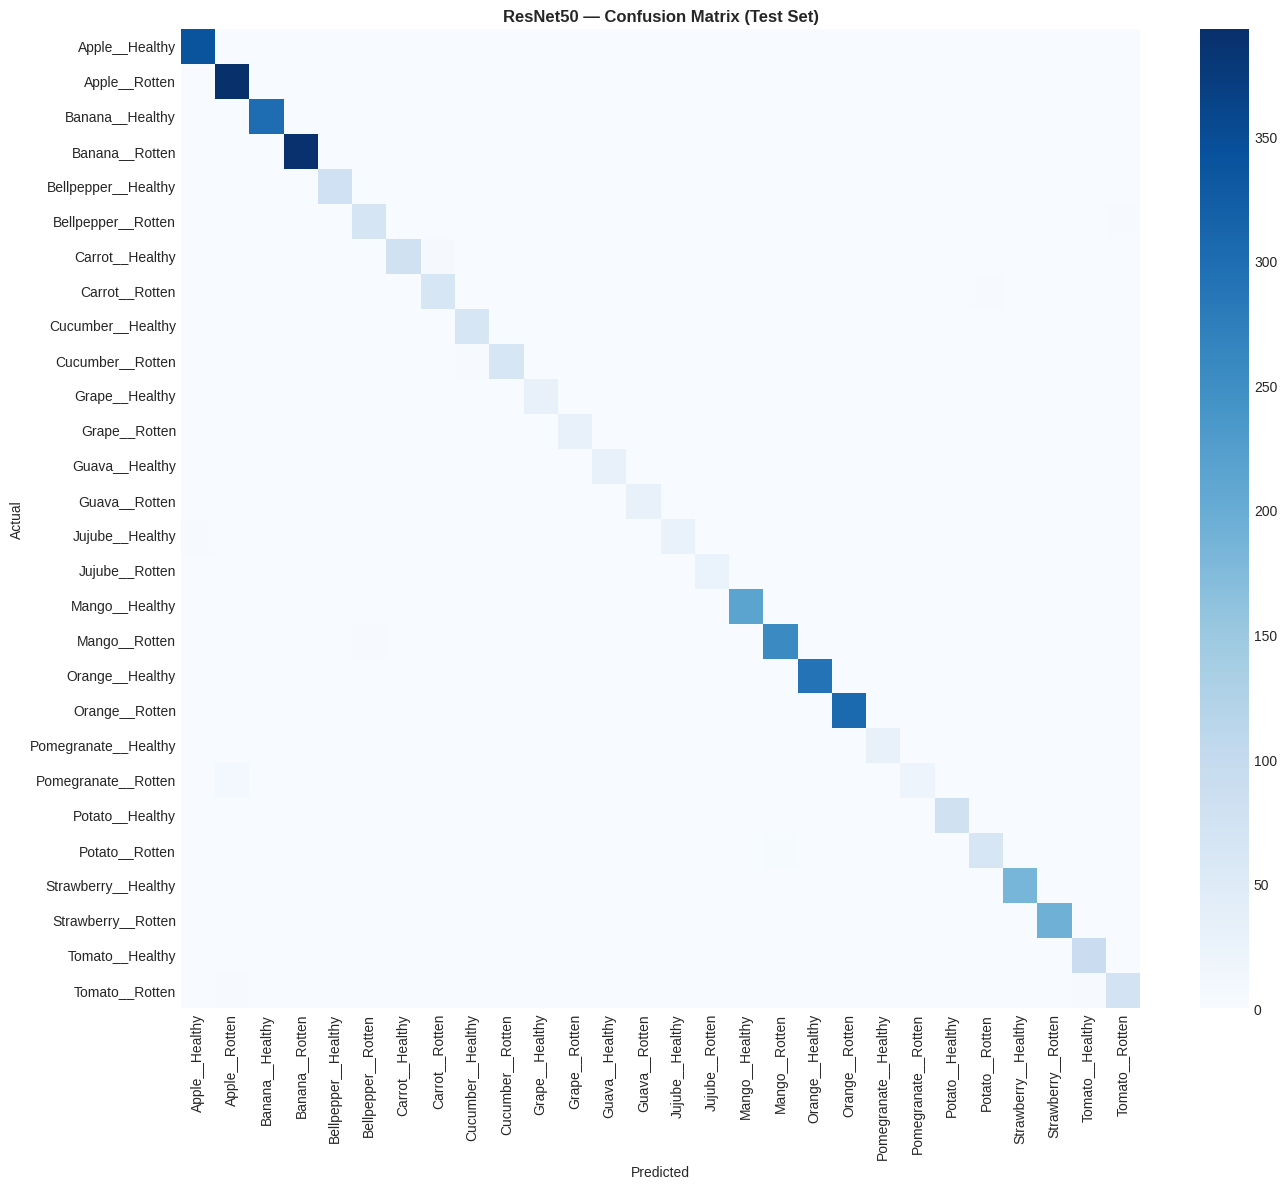


Top confused class pairs (true → predicted : count):
  Pomegranate__Rotten            → Apple__Rotten                  : 9
  Carrot__Healthy                → Carrot__Rotten                 : 5
  Potato__Rotten                 → Mango__Rotten                  : 4
  Bellpepper__Rotten             → Tomato__Rotten                 : 3
  Cucumber__Rotten               → Cucumber__Healthy              : 3
  Carrot__Rotten                 → Potato__Rotten                 : 2
  Jujube__Healthy                → Apple__Healthy                 : 2
  Mango__Rotten                  → Bellpepper__Rotten             : 2
  Tomato__Rotten                 → Apple__Rotten                  : 2
  Tomato__Rotten                 → Tomato__Healthy                : 2

[+] Per-class F1 for minority fruits:
  Grape__Healthy                 F1=1.000 support=30.0
  Grape__Rotten                  F1=1.000 support=30.0
  Guava__Healthy                 F1=1.000 support=30.0
  Guava__Rotten                  F1=1.000 

In [ ]:
# ---- Confusion matrix ----
cm = confusion_matrix(all_labels, all_preds)
metrics_log["confusion_matrix"] = cm.tolist()

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("ResNet50 — Confusion Matrix (Test Set)", fontweight="bold")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("resnet50_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Top confused class pairs ----
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

top_confusions = []
for i in range(len(classes)):
    for j in range(len(classes)):
        if cm_no_diag[i, j] > 0:
            top_confusions.append((classes[i], classes[j], cm_no_diag[i, j]))

top_confusions = sorted(top_confusions, key=lambda x: x[2], reverse=True)[:10]

print("\nTop confused class pairs (true → predicted : count):")
for true_c, pred_c, count in top_confusions:
    print(f"  {true_c:30s} → {pred_c:30s} : {count}")

# ---- Minority-class analysis ----
minority_class_labels = [c for c in classes if c.split("__")[0] in MINORITY_FRUITS]
minority_report = {
    c: metrics_log["classification_report"][c]
    for c in minority_class_labels if c in metrics_log["classification_report"]
}

print("\n[+] Per-class F1 for minority fruits:")
for c, stats in minority_report.items():
    print(f"  {c:30s} F1={stats['f1-score']:.3f} support={stats['support']}")


In [ ]:
total_training_time = metrics_log["stage1_training_time_sec"] + metrics_log["stage2_training_time_sec"]
metrics_log["total_training_time_sec"] = total_training_time

os.makedirs("metrics", exist_ok=True)
with open("metrics/resnet50_metrics.json", "w") as f:
    json.dump(metrics_log, f, indent=2)

print(f"[+] ResNet50 metrics saved to metrics/resnet50_metrics.json")
print(f"[+] Total training time: {total_training_time:.1f}s")


[+] ResNet50 metrics saved to metrics/resnet50_metrics.json
[+] Total training time: 4284.3s


## Section 5 — Transfer Learning: MobileNetV2
Applies the same methodology using MobileNetV2 (ImageNet weights) — a lighter and faster model at inference — with precise inference-time logging, since speed is its key competitive advantage in the Section 6 comparison.

In [ ]:
# Load fixed dataset splits
train_df = pd.read_csv("splits/train_df.csv")
val_df = pd.read_csv("splits/val_df.csv")
test_df = pd.read_csv("splits/test_df.csv")


# Load class-to-index mapping
with open("splits/class_to_idx.json") as f:
    class_to_idx = json.load(f)


# Load shared augmentation configuration
with open("splits/augmentation_config.json") as f:
    aug_config = json.load(f)


# Class information
classes = sorted(
    class_to_idx,
    key=class_to_idx.get
)

NUM_CLASSES = len(classes)


# Shared augmentation settings
MINORITY_FRUITS = set(
    aug_config["minority_fruits"]
)

ROUND_SYMMETRIC_FRUITS = set(
    aug_config["round_symmetric_fruits"]
)

STANDARD_AUG = aug_config[
    "standard_augmentation"
]

MINORITY_AUG = aug_config[
    "minority_augmentation"
]


print(
    f"[+] Train: {len(train_df):,}"
)

print(
    f"[+] Val:   {len(val_df):,}"
)

print(
    f"[+] Test:  {len(test_df):,}"
)

print(
    f"[+] Number of classes: {NUM_CLASSES}"
)

print(
    f"[+] Minority fruits: "
    f"{sorted(MINORITY_FRUITS)}"
)

print(
    f"[+] Round/symmetric fruits: "
    f"{sorted(ROUND_SYMMETRIC_FRUITS)}"
)

[+] Train: 18,107
[+] Val:   3,880
[+] Test:  3,881
[+] Number of classes: 28
[+] Minority fruits: ['Grape', 'Guava', 'Jujube', 'Pomegranate']
[+] Round/symmetric fruits: ['Apple', 'Grape', 'Guava', 'Orange', 'Pomegranate', 'Tomato']


In [ ]:
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


def build_train_transform(
    aug_cfg,
    fruit_name
):
    """
    Build the class-aware augmentation pipeline
    defined in Task 1.
    """

    ops = [
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(
            p=aug_cfg.get(
                "horizontal_flip_p",
                0.5
            )
        )
    ]

    # Vertical flip for round/symmetric fruits
    if fruit_name in ROUND_SYMMETRIC_FRUITS:

        ops.append(
            transforms.RandomVerticalFlip(
                p=aug_cfg.get(
                    "vertical_flip_p",
                    0.3
                )
            )
        )

    # Rotation
    rotation_degrees = aug_cfg.get(
        "rotation_degrees",
        15
    )

    ops.append(
        transforms.RandomRotation(
            degrees=rotation_degrees
        )
    )

    # Minority-class augmentation
    if fruit_name in MINORITY_FRUITS:

        color_cfg = aug_cfg.get(
            "color_jitter",
            {}
        )

        ops.append(
            transforms.ColorJitter(
                brightness=color_cfg.get(
                    "brightness",
                    0.3
                ),
                contrast=color_cfg.get(
                    "contrast",
                    0.3
                ),
                saturation=color_cfg.get(
                    "saturation",
                    0.3
                ),
                hue=color_cfg.get(
                    "hue",
                    0.1
                )
            )
        )

        affine_cfg = aug_cfg.get(
            "random_affine",
            {}
        )

        ops.append(
            transforms.RandomAffine(
                degrees=0,
                translate=tuple(
                    affine_cfg.get(
                        "translate",
                        [0.1, 0.1]
                    )
                ),
                scale=tuple(
                    affine_cfg.get(
                        "scale",
                        [0.85, 1.15]
                    )
                )
            )
        )

    # Convert to tensor + ImageNet normalization
    ops.extend([
        transforms.ToTensor(),
        transforms.Normalize(
            IMAGENET_MEAN,
            IMAGENET_STD
        )
    ])

    return transforms.Compose(ops)


# Get the actual fruit names from the dataset
fruit_types = sorted(
    train_df["fruit"].unique()
)

print(
    "[+] Fruit types found:",
    fruit_types
)

print(
    "[+] Number of fruit types:",
    len(fruit_types)
)


# Build transforms using actual fruit names
standard_transforms = {
    fruit: build_train_transform(
        STANDARD_AUG,
        fruit
    )
    for fruit in fruit_types
    if fruit not in MINORITY_FRUITS
}


minority_transforms = {
    fruit: build_train_transform(
        MINORITY_AUG,
        fruit
    )
    for fruit in fruit_types
    if fruit in MINORITY_FRUITS
}


print(
    "[+] Standard transforms:",
    len(standard_transforms)
)

print(
    "[+] Minority transforms:",
    len(minority_transforms)
)


# Evaluation transform
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


class FreshnessDataset(Dataset):
    """
    Dataset using the class-aware augmentation
    strategy defined in Task 1.
    """

    def __init__(
        self,
        df,
        class_to_idx,
        minority_fruits,
        is_train=False
    ):

        df = df.copy()

        # Optional minority oversampling
        if is_train:

            oversample_factor = MINORITY_AUG.get(
                "oversample_factor",
                1
            )

            minority_rows = df[
                df["fruit"].isin(minority_fruits)
            ]

            if oversample_factor > 1:

                df = pd.concat(
                    [df] +
                    [minority_rows] *
                    (oversample_factor - 1),
                    ignore_index=True
                )

        self.filepaths = df[
            "filepath"
        ].values

        self.fruits = df[
            "fruit"
        ].values

        self.labels = (
            df["class_label"]
            .map(class_to_idx)
            .values
        )

        self.is_train = is_train

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):

        img = Image.open(
            self.filepaths[idx]
        ).convert("RGB")

        fruit = self.fruits[idx]

        if self.is_train:

            if fruit in MINORITY_FRUITS:

                transform = minority_transforms[
                    fruit
                ]

            else:

                transform = standard_transforms[
                    fruit
                ]

        else:

            transform = eval_transform

        img = transform(img)

        label = self.labels[idx]

        return img, label


# Create datasets
train_ds = FreshnessDataset(
    train_df,
    class_to_idx,
    MINORITY_FRUITS,
    is_train=True
)

val_ds = FreshnessDataset(
    val_df,
    class_to_idx,
    MINORITY_FRUITS,
    is_train=False
)

test_ds = FreshnessDataset(
    test_df,
    class_to_idx,
    MINORITY_FRUITS,
    is_train=False
)


# DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)


print(
    f"[+] Train samples: "
    f"{len(train_ds):,}"
)

print(
    f"[+] Train batches: "
    f"{len(train_loader)}"
)

print(
    f"[+] Val batches: "
    f"{len(val_loader)}"
)

print(
    f"[+] Test batches: "
    f"{len(test_loader)}"
)

[+] Fruit types found: ['Apple', 'Banana', 'Bellpepper', 'Carrot', 'Cucumber', 'Grape', 'Guava', 'Jujube', 'Mango', 'Orange', 'Pomegranate', 'Potato', 'Strawberry', 'Tomato']
[+] Number of fruit types: 14
[+] Standard transforms: 10
[+] Minority transforms: 4
[+] Train samples: 18,107
[+] Train batches: 566
[+] Val batches: 122
[+] Test batches: 122


In [ ]:
def build_mobilenetv2(num_classes):
    model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

model = build_mobilenetv2(NUM_CLASSES).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"[+] Total parameters: {total_params:,}")
print(f"[+] Trainable parameters: {trainable_params:,}")


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 162MB/s]

[+] Total parameters: 2,259,740
[+] Trainable parameters: 2,259,740


In [ ]:
metrics_log = new_metrics_log("MobileNetV2")
metrics_log["num_params_total"] = total_params


In [ ]:
# ---- Stage 1: Feature Extraction (Backbone Frozen) ----
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the new classification head (classifier[1])
for param in model.classifier[1].parameters():
    param.requires_grad = True

trainable_stage1 = sum(p.numel() for p in model.parameters() if p.requires_grad)
metrics_log["num_params_trainable_stage1"] = trainable_stage1

print(f"[+] Trainable parameters in Stage 1: {trainable_stage1:,}")
print(f"[+] Percentage of total: {trainable_stage1 / total_params * 100:.2f}%")

criterion = nn.CrossEntropyLoss()
optimizer_stage1 = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)
STAGE1_EPOCHS = 5

stage1_time = train_stage(
    model, train_loader, val_loader, criterion, optimizer_stage1,
    epochs=STAGE1_EPOCHS, history=metrics_log["stage1_history"]
)
metrics_log["stage1_training_time_sec"] = stage1_time
print(f"[+] Stage 1 completed in {stage1_time:.1f}s")
print(f"[+] Average time per epoch: {stage1_time / STAGE1_EPOCHS:.1f}s")


[+] Trainable parameters in Stage 1: 35,868
[+] Percentage of total: 1.59%


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/5 | train_loss=0.9317 train_acc=0.7840 | val_loss=0.4582 val_acc=0.8899


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 2/5 | train_loss=0.3966 train_acc=0.8968 | val_loss=0.3343 val_acc=0.9077


...

Epoch 3/5 | train_loss=0.3118 train_acc=0.9136 | val_loss=0.2736 val_acc=0.9245


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 4/5 | train_loss=0.2687 train_acc=0.9235 | val_loss=0.2441 val_acc=0.9291


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 5/5 | train_loss=0.2414 train_acc=0.9285 | val_loss=0.2259 val_acc=0.9363
[+] Stage 1 completed in 1231.4s
[+] Average time per epoch: 246.3s


In [ ]:
# ---- Stage 2: Full Fine-tuning (Backbone Unfrozen) ----
for param in model.parameters():
    param.requires_grad = True

trainable_stage2 = sum(p.numel() for p in model.parameters() if p.requires_grad)
metrics_log["num_params_trainable_stage2"] = trainable_stage2

print(f"[+] Trainable parameters in Stage 2: {trainable_stage2:,}")
print(f"[+] Percentage of total: {trainable_stage2 / total_params * 100:.2f}%")

optimizer_stage2 = optim.Adam(model.parameters(), lr=1e-4)
scheduler_stage2 = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage2, mode="min", factor=0.5, patience=2
)
STAGE2_EPOCHS = 10

stage2_time = train_stage(
    model, train_loader, val_loader, criterion, optimizer_stage2,
    epochs=STAGE2_EPOCHS, history=metrics_log["stage2_history"], scheduler=scheduler_stage2
)
metrics_log["stage2_training_time_sec"] = stage2_time
print(f"[+] Stage 2 completed in {stage2_time:.1f}s")

os.makedirs("models", exist_ok=True)
torch.save(model.state_dict(), "models/mobilenetv2_finetuned.pth")
print("[+] Model weights saved to models/mobilenetv2_finetuned.pth")


[+] Trainable parameters in Stage 2: 2,259,740
[+] Percentage of total: 100.00%


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 1/10 | train_loss=0.1475 train_acc=0.9533 | val_loss=0.1149 val_acc=0.9624


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 2/10 | train_loss=0.0767 train_acc=0.9764 | val_loss=0.0935 val_acc=0.9711


...

Epoch 8/10 | train_loss=0.0140 train_acc=0.9962 | val_loss=0.0806 val_acc=0.9758


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 9/10 | train_loss=0.0120 train_acc=0.9966 | val_loss=0.0839 val_acc=0.9747


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch 10/10 | train_loss=0.0105 train_acc=0.9965 | val_loss=0.0660 val_acc=0.9820
[+] Stage 2 completed in 2621.4s
[+] Model weights saved to models/mobilenetv2_finetuned.pth


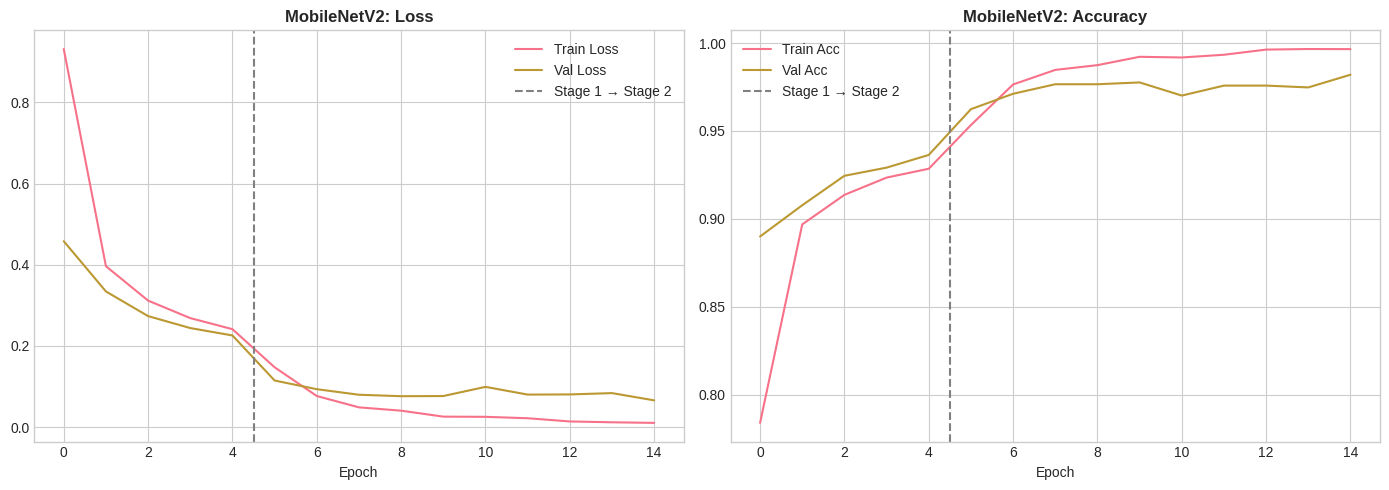

In [ ]:
plot_training_curves(metrics_log, "MobileNetV2")


In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

test_acc = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="macro", zero_division=0
)

metrics_log["test_accuracy"] = test_acc
metrics_log["test_precision_macro"] = precision
metrics_log["test_recall_macro"] = recall
metrics_log["test_f1_macro"] = f1
metrics_log["classification_report"] = classification_report(
    all_labels, all_preds, target_names=classes, zero_division=0, output_dict=True
)

print(f"[+] Test Accuracy: {test_acc * 100:.2f}%")
print(f"[+] Test Precision (macro): {precision:.4f}")
print(f"[+] Test Recall (macro): {recall:.4f}")
print(f"[+] Test F1 (macro): {f1:.4f}")

# ---- Inference speed benchmark ----
sample_batch, _ = next(iter(test_loader))
sample_image = sample_batch[:1].to(DEVICE)

with torch.no_grad():
    for _ in range(5):
        _ = model(sample_image)

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

n_runs = 100
start = time.time()
with torch.no_grad():
    for _ in range(n_runs):
        _ = model(sample_image)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

inference_ms = (time.time() - start) / n_runs * 1000
metrics_log["inference_time_ms_per_image"] = inference_ms
print(f"[+] Inference time: {inference_ms:.2f} ms/image")


[+] Test Accuracy: 98.30%
[+] Test Precision (macro): 0.9772
[+] Test Recall (macro): 0.9598
[+] Test F1 (macro): 0.9679
[+] Inference time: 5.21 ms/image


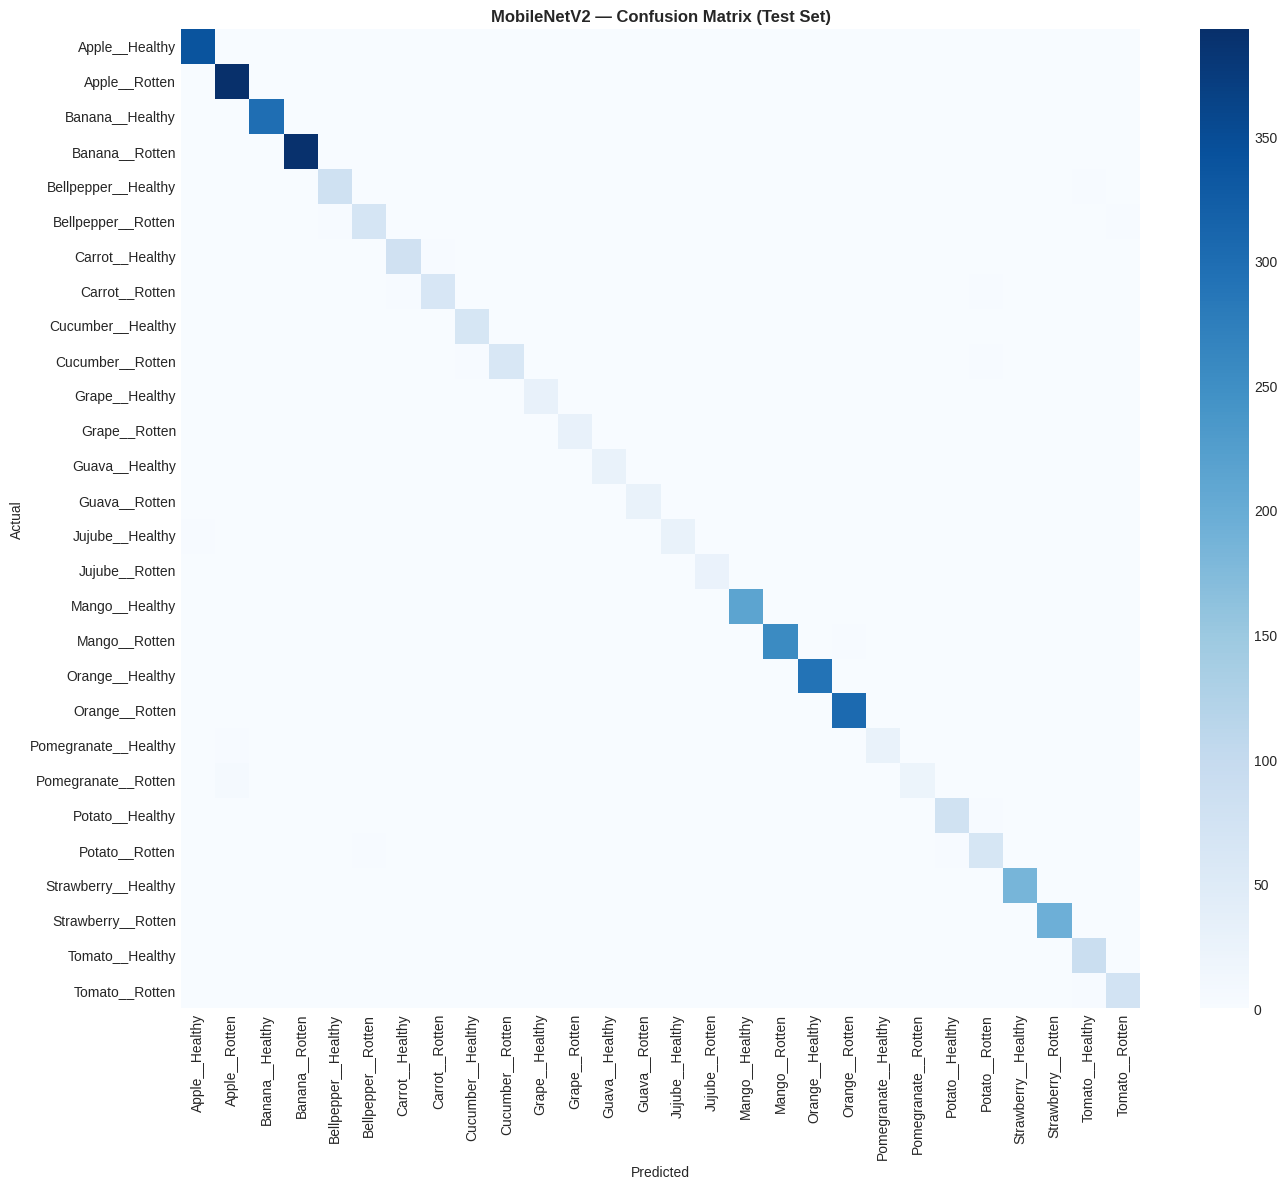


Top confused class pairs (true → predicted : count):
  Pomegranate__Rotten            → Apple__Rotten                  : 7
  Bellpepper__Rotten             → Bellpepper__Healthy            : 3
  Bellpepper__Rotten             → Tomato__Rotten                 : 3
  Carrot__Healthy                → Carrot__Rotten                 : 3
  Carrot__Rotten                 → Carrot__Healthy                : 3
  Cucumber__Rotten               → Potato__Rotten                 : 3
  Bellpepper__Healthy            → Tomato__Healthy                : 2
  Carrot__Rotten                 → Potato__Rotten                 : 2
  Cucumber__Rotten               → Cucumber__Healthy              : 2
  Jujube__Healthy                → Apple__Healthy                 : 2

[+] Per-class F1 for minority fruits:
  Grape__Healthy                 F1=1.000 support=30.0
  Grape__Rotten                  F1=1.000 support=30.0
  Guava__Healthy                 F1=0.983 support=30.0
  Guava__Rotten                  F1=0.966 

In [ ]:
# ---- Confusion matrix ----
cm = confusion_matrix(all_labels, all_preds)
metrics_log["confusion_matrix"] = cm.tolist()

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("MobileNetV2 — Confusion Matrix (Test Set)", fontweight="bold")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("mobilenetv2_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Top confused class pairs ----
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)

top_confusions = []
for i in range(len(classes)):
    for j in range(len(classes)):
        if cm_no_diag[i, j] > 0:
            top_confusions.append((classes[i], classes[j], cm_no_diag[i, j]))

top_confusions = sorted(top_confusions, key=lambda x: x[2], reverse=True)[:10]

print("\nTop confused class pairs (true → predicted : count):")
for true_c, pred_c, count in top_confusions:
    print(f"  {true_c:30s} → {pred_c:30s} : {count}")

# ---- Minority-class analysis ----
minority_class_labels = [c for c in classes if c.split("__")[0] in MINORITY_FRUITS]
minority_report = {
    c: metrics_log["classification_report"][c]
    for c in minority_class_labels if c in metrics_log["classification_report"]
}

print("\n[+] Per-class F1 for minority fruits:")
for c, stats in minority_report.items():
    print(f"  {c:30s} F1={stats['f1-score']:.3f} support={stats['support']}")


In [ ]:
total_training_time = metrics_log["stage1_training_time_sec"] + metrics_log["stage2_training_time_sec"]
metrics_log["total_training_time_sec"] = total_training_time

os.makedirs("metrics", exist_ok=True)
with open("metrics/mobilenetv2_metrics.json", "w") as f:
    json.dump(metrics_log, f, indent=2)

print(f"[+] MobileNetV2 metrics saved to metrics/mobilenetv2_metrics.json")
print(f"[+] Total training time: {total_training_time:.1f}s")


[+] MobileNetV2 metrics saved to metrics/mobilenetv2_metrics.json
[+] Total training time: 3852.9s


## Section 6 — Evaluation & Comparison
Aggregates the results of all three deep learning models, builds comparison tables and charts (accuracy, precision, recall, F1, inference speed), analyzes confusion matrices and the most confused class pairs, studies the effect of class imbalance on minority classes, and summarizes the final conclusions.

In [ ]:
# ---- 6.1 تحميل نتائج كل النماذج من الصيغة المشتركة ----
with open("metrics/classical_baseline_metrics.json") as f:
    m_classical = json.load(f)
with open("metrics/alexnet_metrics.json") as f:
    m_alexnet = json.load(f)
with open("metrics/resnet50_metrics.json") as f:
    m_resnet = json.load(f)
with open("metrics/mobilenetv2_metrics.json") as f:
    m_mobilenet = json.load(f)

with open("splits/class_to_idx.json") as f:
    class_to_idx = json.load(f)
classes = sorted(class_to_idx, key=class_to_idx.get)

all_models = {
    m_classical["model_name"]: m_classical,
    "AlexNet": m_alexnet,
    "ResNet50": m_resnet,
    "MobileNetV2": m_mobilenet,
}
print("Loaded models:", list(all_models.keys()))


Loaded models: ['SVM_Baseline', 'AlexNet', 'ResNet50', 'MobileNetV2']


In [ ]:
# ---- 6.2 جدول مقارنة موحّد ----
comparison_rows = []
for name, m in all_models.items():
    is_classical = "history" not in str(m.get("stage2_history", {})) or m["num_params_trainable_stage2"] is None
    total_params = m["num_params_total"]
    train_time = m.get("total_training_time_sec") or m.get("stage1_training_time_sec")
    comparison_rows.append({
        "Model": name,
        "Type": "Classical ML" if m is m_classical else "Deep Learning",
        "Accuracy": m["test_accuracy"],
        "Precision": m["test_precision_macro"],
        "Recall": m["test_recall_macro"],
        "F1": m["test_f1_macro"],
        "Params": total_params,
        "Train Time (s)": round(train_time, 1) if train_time else None,
        "Inference (ms/img)": round(m["inference_time_ms_per_image"], 2),
    })

comparison_df = (pd.DataFrame(comparison_rows)
                  .sort_values("Accuracy", ascending=False)
                  .reset_index(drop=True))
comparison_df.insert(0, "Rank", comparison_df.index + 1)

comparison_df.to_csv("metrics/model_comparison.csv", index=False)
print("Saved metrics/model_comparison.csv")
comparison_df


Saved metrics/model_comparison.csv


,Rank,Model,Type,Accuracy,Precision,Recall,F1,Params,Train Time (s),Inference (ms/img)
0,1,ResNet50,Deep Learning,0.983767,0.978570,0.963022,0.969316,23565404,4284.3,5.96
1,2,MobileNetV2,Deep Learning,0.982994,0.977245,0.959790,0.967872,2259740,3852.9,5.21
2,3,AlexNet,Deep Learning,0.958774,0.918184,0.927887,0.921590,57118556,3723.3,2.11
3,4,SVM_Baseline,Classical ML,0.788457,0.780468,0.710038,0.738983,106858380,1769.0,130.49


/tmp/ipykernel_3787/3045047765.py:12: UserWarning: Glyph 1605 (\N{ARABIC LETTER MEEM}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/3045047765.py:12: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.tight_layout()
/tmp/ipykernel_3787/3045047765.py:12: UserWarning: Glyph 1602 (\N{ARABIC LETTER QAF}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/3045047765.py:12: UserWarning: Glyph 1575 (\N{ARABIC LETTER ALEF}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/3045047765.py:12: UserWarning: Glyph 1585 (\N{ARABIC LETTER REH}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/3045047765.py:12: UserWarning: Glyph 1606 (\N{ARABIC LETTER NOON}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/3045047765.py:12: UserWarning: Glyph 1577 (\N{ARABIC LETTER TEH MARBUTA}) missing from font(s) Liberation Sans.
  plt.tight_l

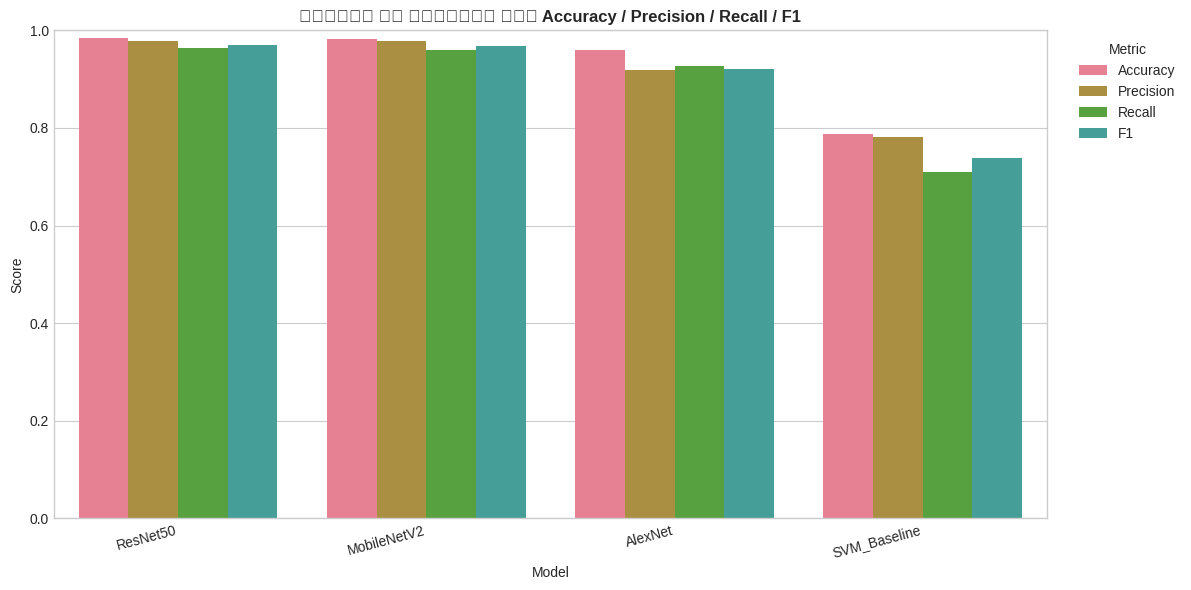

In [ ]:
# ---- 6.3 مقارنة متعددة المقاييس: Accuracy / Precision / Recall / F1 ----
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1"]
plot_df = comparison_df.melt(id_vars="Model", value_vars=metrics_to_plot,
                              var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 6))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric")
plt.title("مقارنة كل النماذج عبر Accuracy / Precision / Recall / F1", fontweight="bold")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("metrics/all_models_metric_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


/tmp/ipykernel_3787/2605201865.py:14: UserWarning: Glyph 1571 (\N{ARABIC LETTER ALEF WITH HAMZA ABOVE}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/2605201865.py:14: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.tight_layout()
/tmp/ipykernel_3787/2605201865.py:14: UserWarning: Glyph 1602 (\N{ARABIC LETTER QAF}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/2605201865.py:14: UserWarning: Glyph 1604 (\N{ARABIC LETTER LAM}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/2605201865.py:14: UserWarning: Glyph 1587 (\N{ARABIC LETTER SEEN}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/2605201865.py:14: UserWarning: Glyph 1585 (\N{ARABIC LETTER REH}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/2605201865.py:14: UserWarning: Glyph 1593 (\N{ARABIC LETTER AIN}) missing from font(s) Liberation Sans.
  plt

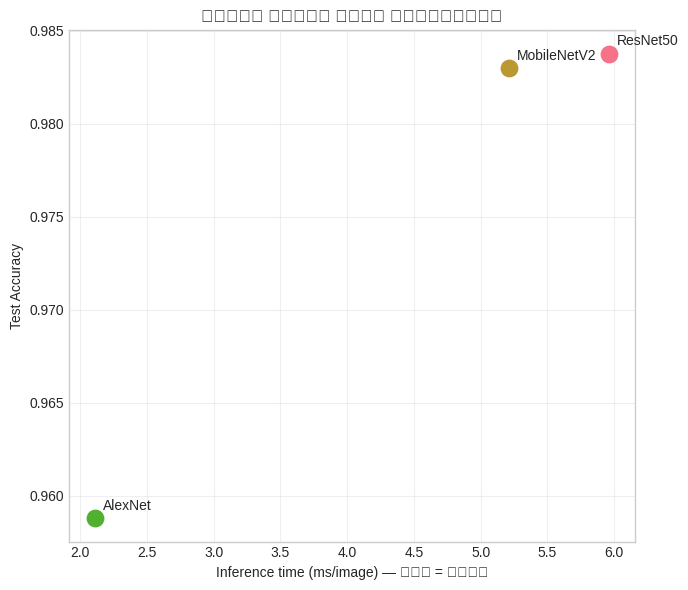

In [ ]:
# ---- 6.4 المفاضلة بين الدقة وسرعة الاستدلال (Accuracy vs. Efficiency) ----
deep_df = comparison_df[comparison_df["Type"] == "Deep Learning"]

plt.figure(figsize=(7, 6))
for _, row in deep_df.iterrows():
    plt.scatter(row["Inference (ms/img)"], row["Accuracy"], s=140)
    plt.annotate(row["Model"], (row["Inference (ms/img)"], row["Accuracy"]),
                 xytext=(6, 6), textcoords="offset points", fontsize=10)

plt.xlabel("Inference time (ms/image) — أقل = أسرع")
plt.ylabel("Test Accuracy")
plt.title("الدقة مقابل سرعة الاستدلال", fontweight="bold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("metrics/accuracy_vs_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()


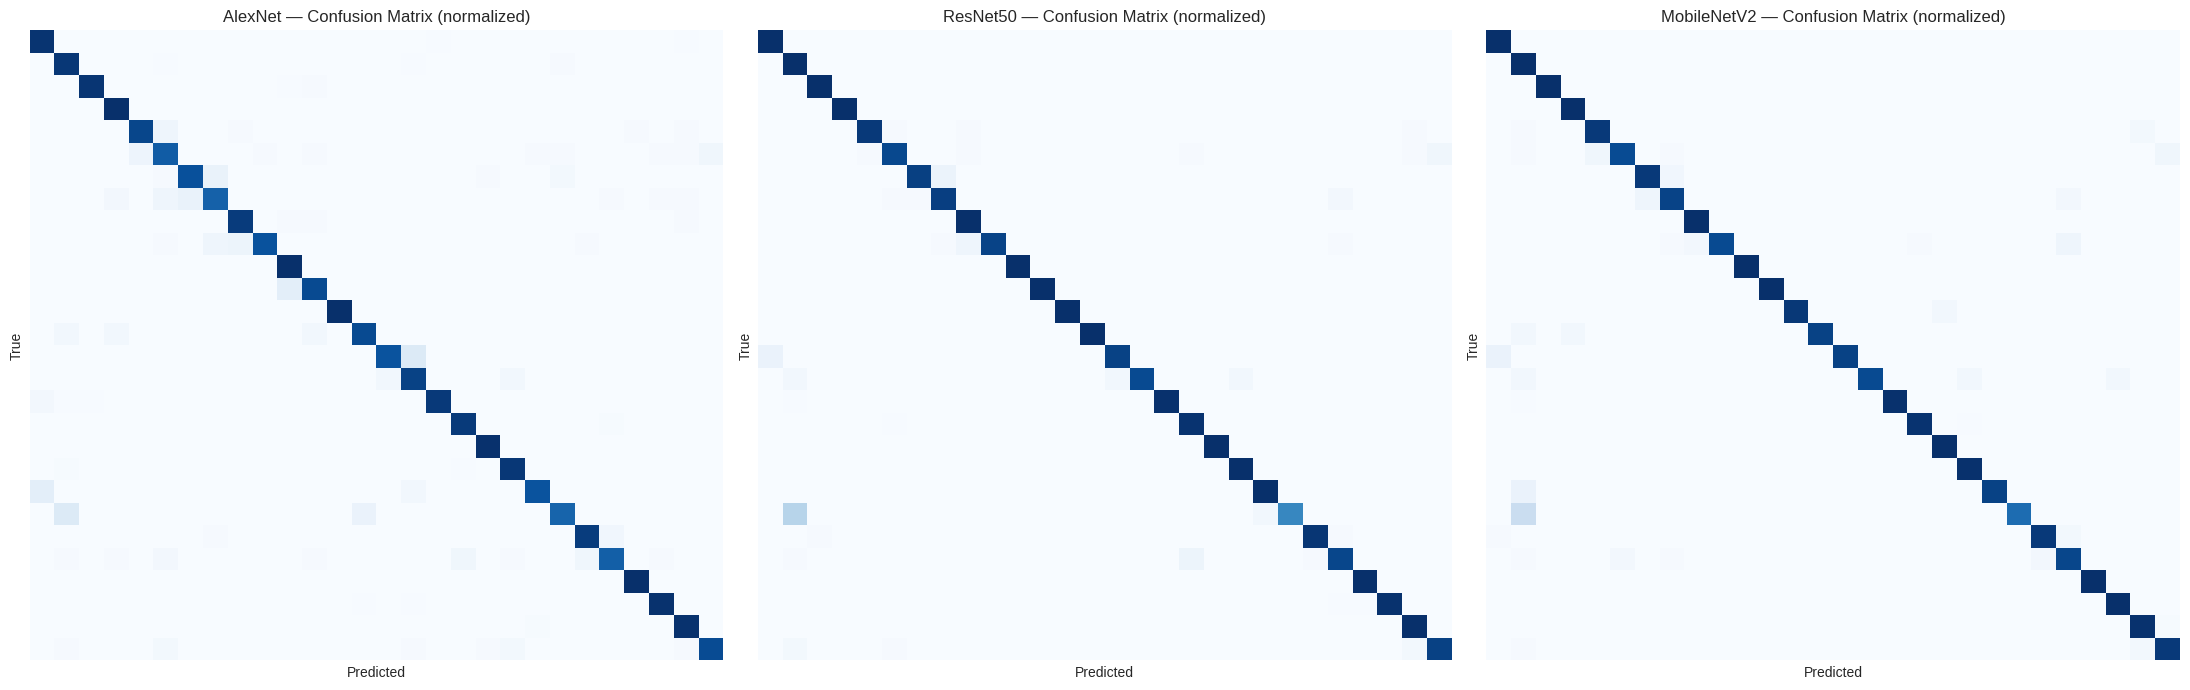

In [ ]:
# ---- 6.5 مصفوفات الالتباس (Confusion Matrices) للنماذج العميقة الثلاثة ----
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

for ax, (name, m) in zip(axes, [("AlexNet", m_alexnet),
                                  ("ResNet50", m_resnet),
                                  ("MobileNetV2", m_mobilenet)]):
    cm = np.array(m["confusion_matrix"], dtype=float)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, ax=ax, cmap="Blues", cbar=False, vmin=0, vmax=1,
                xticklabels=False, yticklabels=False)
    ax.set_title(f"{name} — Confusion Matrix (normalized)")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")

plt.tight_layout()
plt.savefig("metrics/all_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
# مع 28 فئة اتشالت الـ tick labels للوضوح — الخلية الجاية بتوضح أكتر الأزواج المتلخبطة بالاسم.


In [ ]:
# ---- 6.6 أكثر أزواج الفئات تلخبطًا (Top confused class pairs) لأفضل نموذج ----
best_model_name = comparison_df.iloc[0]["Model"]
print(f"Best performing model: {best_model_name}")

best_m = all_models[best_model_name]
cm_best = np.array(best_m["confusion_matrix"])
cm_off = cm_best.copy()
np.fill_diagonal(cm_off, 0)

pairs = [(classes[i], classes[j], cm_off[i, j])
         for i in range(cm_off.shape[0]) for j in range(cm_off.shape[1])
         if cm_off[i, j] > 0]

top_confused = (pd.DataFrame(pairs, columns=["True Class", "Predicted As", "Count"])
                  .sort_values("Count", ascending=False)
                  .head(10)
                  .reset_index(drop=True))
print("\nأكثر 10 أزواج فئات بيتلخبطوا مع بعض:")
top_confused


Best performing model: ResNet50

أكثر 10 أزواج فئات بيتلخبطوا مع بعض:


,True Class,Predicted As,Count
0,Pomegranate__Rotten,Apple__Rotten,9
1,Carrot__Healthy,Carrot__Rotten,5
2,Potato__Rotten,Mango__Rotten,4
3,Bellpepper__Rotten,Tomato__Rotten,3
4,Cucumber__Rotten,Cucumber__Healthy,3
5,Mango__Rotten,Bellpepper__Rotten,2
6,Jujube__Healthy,Apple__Healthy,2
7,Tomato__Rotten,Tomato__Healthy,2
8,Tomato__Rotten,Apple__Rotten,2
9,Carrot__Rotten,Potato__Rotten,2


الارتباط بين حجم الفئة والـ F1 (لـ ResNet50): 0.395


/tmp/ipykernel_3787/223021143.py:24: UserWarning: Glyph 1593 (\N{ARABIC LETTER AIN}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/223021143.py:24: UserWarning: Matplotlib currently does not support Arabic natively.
  plt.tight_layout()
/tmp/ipykernel_3787/223021143.py:24: UserWarning: Glyph 1583 (\N{ARABIC LETTER DAL}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/223021143.py:24: UserWarning: Glyph 1589 (\N{ARABIC LETTER SAD}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/223021143.py:24: UserWarning: Glyph 1608 (\N{ARABIC LETTER WAW}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/223021143.py:24: UserWarning: Glyph 1585 (\N{ARABIC LETTER REH}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipykernel_3787/223021143.py:24: UserWarning: Glyph 1575 (\N{ARABIC LETTER ALEF}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/tmp/ipyk

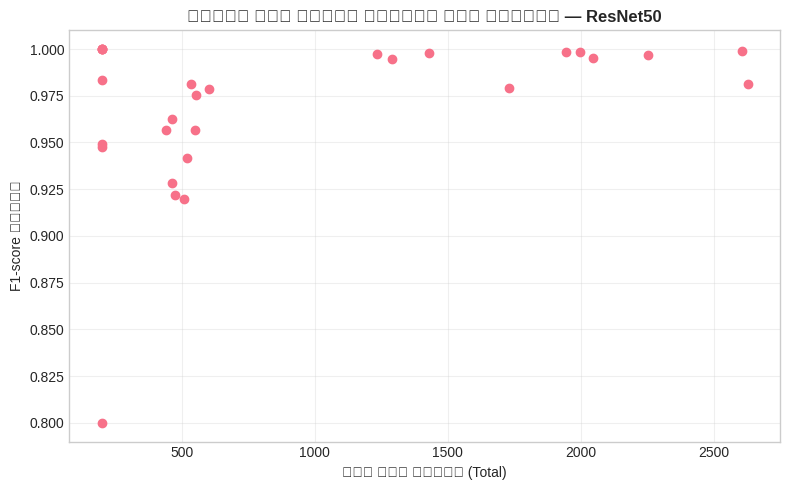


أضعف 5 فئات من ناحية F1:


,Class,Total Images,Test Support,F1
21,Pomegranate__Rotten,199,30.0,0.800000
5,Bellpepper__Rotten,510,76.0,0.920000
23,Potato__Rotten,474,71.0,0.921986
7,Carrot__Rotten,464,69.0,0.928571
27,Tomato__Rotten,519,78.0,0.941935


In [ ]:
# ---- 6.7 تأثير عدم توازن الفئات: هل الفئات القليلة أداؤها أضعف؟ ----
train_df_all = pd.read_csv("splits/train_df.csv")
val_df_all = pd.read_csv("splits/val_df.csv")
test_df_all = pd.read_csv("splits/test_df.csv")
full_df = pd.concat([train_df_all, val_df_all, test_df_all], ignore_index=True)
class_size = full_df["class_label"].value_counts()

report_best = best_m["classification_report"]
per_class_df = pd.DataFrame([
    {"Class": c, "Total Images": class_size.get(c, np.nan),
     "Test Support": report_best[c]["support"], "F1": report_best[c]["f1-score"]}
    for c in classes if c in report_best
]).sort_values("F1")

corr = per_class_df["Total Images"].corr(per_class_df["F1"])
print(f"الارتباط بين حجم الفئة والـ F1 (لـ {best_model_name}): {corr:.3f}")

plt.figure(figsize=(8, 5))
plt.scatter(per_class_df["Total Images"], per_class_df["F1"])
plt.xlabel("عدد صور الفئة (Total)")
plt.ylabel("F1-score للفئة")
plt.title(f"تأثير عدم توازن الفئات على الأداء — {best_model_name}", fontweight="bold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("metrics/class_imbalance_vs_f1.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nأضعف 5 فئات من ناحية F1:")
per_class_df.head(5)


In [ ]:
# ---- 6.8 مقارنة أداء الفئات القليلة (Minority) مقابل باقي الفئات عبر كل النماذج ----
with open("splits/augmentation_config.json") as f:
    aug_config = json.load(f)
minority_fruits = set(aug_config["minority_fruits"])

rows = []
for name, m in [("AlexNet", m_alexnet), ("ResNet50", m_resnet), ("MobileNetV2", m_mobilenet)]:
    report = m["classification_report"]
    minority_f1 = np.mean([report[c]["f1-score"] for c in classes
                            if c.split("__")[0] in minority_fruits and c in report])
    other_f1 = np.mean([report[c]["f1-score"] for c in classes
                         if c.split("__")[0] not in minority_fruits and c in report])
    rows.append({"Model": name, "Minority Classes F1 (avg)": minority_f1,
                 "Other Classes F1 (avg)": other_f1, "Gap": other_f1 - minority_f1})

minority_gap_df = pd.DataFrame(rows)
print("متوسط F1 للفئات القليلة (Grape/Guava/Jujube/Pomegranate) مقابل باقي الفئات:")
minority_gap_df


متوسط F1 للفئات القليلة (Grape/Guava/Jujube/Pomegranate) مقابل باقي الفئات:


,Model,Minority Classes F1 (avg),Other Classes F1 (avg),Gap
0,AlexNet,0.872216,0.941340,0.069124
1,ResNet50,0.960016,0.973036,0.013020
2,MobileNetV2,0.957917,0.971854,0.013937


## Summary — Completed Tasks

- ✅ Data loading, integrity/quality checks, and class distribution analysis
- ✅ Visual and statistical color exploration per class
- ✅ Full deduplication (MD5 + perceptual hash) before splitting
- ✅ Stratified train/val/test split (70/15/15)
- ✅ Per-class augmentation strategy design
- ✅ Shared metrics logging format for all models
- ✅ Classical CV baseline (HSV histogram + HOG features, Logistic Regression/SVM)
- ✅ Shared training/evaluation functions for all deep learning models
- ✅ Transfer learning with AlexNet (feature extraction + full fine-tuning)
- ✅ Transfer learning with ResNet50 (feature extraction + full fine-tuning)
- ✅ Transfer learning with MobileNetV2 (feature extraction + full fine-tuning)
- ✅ Model comparison across accuracy, precision, recall, F1, and inference speed
- ✅ Confusion matrix analysis and most-confused class pairs
- ✅ Minority-class performance analysis and final conclusions